# Industrial Analytics Project - Group 4

## Business Introduction

The project use MetroPT-3, an open real-world dataset collected from the Air Production Unit (APU) of an operating Metro do Porto train. The UCI release contains 1,516,948 observations and 15 sensor variables, covering pressure, motor current, oil temperature, and digital compressor-control signals between February and August 2020. It is specifically published for predictive maintenance, anomaly detection, failure prediction, and related tasks.
The main purpose of the study is to solve an operational problem frequently on railway: How can a railway operator recognize a developing problem early enough to make a maintenance decision before it disrupts train services?


## Data Understanding

### Importing libraries

In [1]:
import pandas as pd
import warnings
warnings.filterwarnings("ignore")
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import numpy as np

C:\Users\appen\anaconda3\Lib\site-packages\pandas\core\computation\expressions.py:22: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.7' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
C:\Users\appen\anaconda3\Lib\site-packages\pandas\core\arrays\masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.7' currently installed).
  from pandas.core import (


### Describing the data

In [ ]:
#Reading the dataset and printing the head
df = pd.read_csv("MetroPT3_raw_data.csv")
df.head()

,Unnamed: 0,timestamp,TP2,TP3,H1,DV_pressure,Reservoirs,Oil_temperature,Motor_current,COMP,DV_eletric,Towers,MPG,LPS,Pressure_switch,Oil_level,Caudal_impulses
0,0,2020-02-01 00:00:00,-0.012,9.358,9.340,-0.024,9.358,53.600,0.0400,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0
1,10,2020-02-01 00:00:10,-0.014,9.348,9.332,-0.022,9.348,53.675,0.0400,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0
2,20,2020-02-01 00:00:19,-0.012,9.338,9.322,-0.022,9.338,53.600,0.0425,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0
3,30,2020-02-01 00:00:29,-0.012,9.328,9.312,-0.022,9.328,53.425,0.0400,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0
4,40,2020-02-01 00:00:39,-0.012,9.318,9.302,-0.022,9.318,53.475,0.0400,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0


In [3]:
print("The total number of rows, columns: ", df.shape)


The total number of rows, columns:  (1516948, 17)


In [4]:
#Describing the data by columns, non null count and dtype
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1516948 entries, 0 to 1516947
Data columns (total 17 columns):
 #   Column           Non-Null Count    Dtype  
---  ------           --------------    -----  
 0   Unnamed: 0       1516948 non-null  int64  
 1   timestamp        1516948 non-null  str    
 2   TP2              1516948 non-null  float64
 3   TP3              1516948 non-null  float64
 4   H1               1516948 non-null  float64
 5   DV_pressure      1516948 non-null  float64
 6   Reservoirs       1516948 non-null  float64
 7   Oil_temperature  1516948 non-null  float64
 8   Motor_current    1516948 non-null  float64
 9   COMP             1516948 non-null  float64
 10  DV_eletric       1516948 non-null  float64
 11  Towers           1516948 non-null  float64
 12  MPG              1516948 non-null  float64
 13  LPS              1516948 non-null  float64
 14  Pressure_switch  1516948 non-null  float64
 15  Oil_level        1516948 non-null  float64
 16  Caudal_impulses  1516948 non-

In [5]:
#Converting timestamp from str to datetime
df['timestamp'] = pd.to_datetime(df['timestamp'])
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1516948 entries, 0 to 1516947
Data columns (total 17 columns):
 #   Column           Non-Null Count    Dtype         
---  ------           --------------    -----         
 0   Unnamed: 0       1516948 non-null  int64         
 1   timestamp        1516948 non-null  datetime64[us]
 2   TP2              1516948 non-null  float64       
 3   TP3              1516948 non-null  float64       
 4   H1               1516948 non-null  float64       
 5   DV_pressure      1516948 non-null  float64       
 6   Reservoirs       1516948 non-null  float64       
 7   Oil_temperature  1516948 non-null  float64       
 8   Motor_current    1516948 non-null  float64       
 9   COMP             1516948 non-null  float64       
 10  DV_eletric       1516948 non-null  float64       
 11  Towers           1516948 non-null  float64       
 12  MPG              1516948 non-null  float64       
 13  LPS              1516948 non-null  float64       
 14  Pressure_swit

In [6]:
df.describe()

,Unnamed: 0,timestamp,TP2,TP3,H1,DV_pressure,Reservoirs,Oil_temperature,Motor_current,COMP,DV_eletric,Towers,MPG,LPS,Pressure_switch,Oil_level,Caudal_impulses
count,1.516948e+06,1516948,1.516948e+06,1.516948e+06,1.516948e+06,1.516948e+06,1.516948e+06,1.516948e+06,1.516948e+06,1.516948e+06,1.516948e+06,1.516948e+06,1.516948e+06,1.516948e+06,1.516948e+06,1.516948e+06,1.516948e+06
mean,7.584735e+06,2020-05-16 22:58:36.631517,1.367826e+00,8.984611e+00,7.568155e+00,5.595619e-02,8.985233e+00,6.264418e+01,2.050171e+00,8.369568e-01,1.606106e-01,9.198483e-01,8.326640e-01,3.420025e-03,9.914368e-01,9.041556e-01,9.371066e-01
min,0.000000e+00,2020-02-01 00:00:00,-3.200000e-02,7.300000e-01,-3.600000e-02,-3.200000e-02,7.120000e-01,1.540000e+01,2.000000e-02,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,3.792368e+06,2020-03-23 05:05:04.500000,-1.400000e-02,8.492000e+00,8.254000e+00,-2.200000e-02,8.494000e+00,5.777500e+01,4.000000e-02,1.000000e+00,0.000000e+00,1.000000e+00,1.000000e+00,0.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00
50%,7.584735e+06,2020-05-17 08:07:06,-1.200000e-02,8.960000e+00,8.784000e+00,-2.000000e-02,8.960000e+00,6.270000e+01,4.500000e-02,1.000000e+00,0.000000e+00,1.000000e+00,1.000000e+00,0.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00
75%,1.137710e+07,2020-07-10 03:07:27.500000,-1.000000e-02,9.492000e+00,9.374000e+00,-1.800000e-02,9.492000e+00,6.725000e+01,3.807500e+00,1.000000e+00,0.000000e+00,1.000000e+00,1.000000e+00,0.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00
max,1.516947e+07,2020-09-01 03:59:50,1.067600e+01,1.030200e+01,1.028800e+01,9.844000e+00,1.030000e+01,8.905000e+01,9.295000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00
std,4.379053e+06,NaN,3.250930e+00,6.390951e-01,3.333200e+00,3.824015e-01,6.383070e-01,6.516261e+00,2.302053e+00,3.694052e-01,3.671716e-01,2.715280e-01,3.732757e-01,5.838091e-02,9.214078e-02,2.943779e-01,2.427712e-01


In [7]:
df.columns

Index(['Unnamed: 0', 'timestamp', 'TP2', 'TP3', 'H1', 'DV_pressure',
       'Reservoirs', 'Oil_temperature', 'Motor_current', 'COMP', 'DV_eletric',
       'Towers', 'MPG', 'LPS', 'Pressure_switch', 'Oil_level',
       'Caudal_impulses'],
      dtype='str')

In [8]:
df.dtypes

Unnamed: 0                  int64
timestamp          datetime64[us]
TP2                       float64
TP3                       float64
H1                        float64
DV_pressure               float64
Reservoirs                float64
Oil_temperature           float64
Motor_current             float64
COMP                      float64
DV_eletric                float64
Towers                    float64
MPG                       float64
LPS                       float64
Pressure_switch           float64
Oil_level                 float64
Caudal_impulses           float64
dtype: object

### Data Quality

In [9]:
#Counting missing values
df.isnull().sum()

Unnamed: 0         0
timestamp          0
TP2                0
TP3                0
H1                 0
DV_pressure        0
Reservoirs         0
Oil_temperature    0
Motor_current      0
COMP               0
DV_eletric         0
Towers             0
MPG                0
LPS                0
Pressure_switch    0
Oil_level          0
Caudal_impulses    0
dtype: int64

In [10]:
#Counting duplicated entries in a column
df.duplicated().sum()

0

In [11]:
#Returning the number of unique values in a column
df.nunique()

Unnamed: 0         1516948
timestamp          1516948
TP2                   5257
TP3                   3683
H1                    2665
DV_pressure           2257
Reservoirs            3682
Oil_temperature       2462
Motor_current         1809
COMP                     2
DV_eletric               2
Towers                   2
MPG                      2
LPS                      2
Pressure_switch          2
Oil_level                2
Caudal_impulses          2
dtype: int64

In [12]:
#Defining Measurement scales and descriptions
nominal_columns = [
    'COMP',
    'DV_electric',
    'Towers',
    'MPG',
    'LPS',
    'Pressure_switch',
    'Oil_level'
]

interval_columns = [
    'timestamp',
    'Oil_temperature'
]


# Business descriptions
descriptions = {
    'timestamp': 'Date and time of sensor measurement',

    'TP2': 'Pressure at the compressor (bar)',

    'TP3': 'Pressure generated at the pneumatic panel (bar)',

    'H1': 'Pressure resulting from cyclonic separator filter discharge (bar)',

    'DV_pressure': 'Pressure drop during air dryer tower discharge (bar); zero indicates loaded operation',

    'Reservoirs': 'Pressure downstream of the reservoirs (bar); normally close to TP3',

    'Motor_current': 'Motor current (A); approximately 0 A off, 4 A unloaded, 7 A loaded, 9 A starting',

    'Oil_temperature': 'Compressor oil temperature (°C)',

    'COMP': 'Air intake valve signal; active when compressor is off or unloaded',

    'DV_electric': 'Outlet valve signal; active during loaded compressor operation',

    'Towers': 'Air dryer tower selection; 0 = tower 1, 1 = tower 2',

    'MPG': 'Signal initiating loaded operation when APU pressure falls below 8.2 bar',

    'LPS': 'Low-pressure signal activated below 7 bar',

    'Pressure_switch': 'Signal detecting air dryer tower discharge',

    'Oil_level': 'Signal activated when compressor oil level is too low',

    'Caudal_impulses': 'Pulse signal representing air flow from APU to reservoirs'
}

In [13]:
#Creating the descriptive table
rows = []

for col in df.columns:
    # Determine measurement scale
    if col in nominal_columns:
        scale = 'Nominal'
        operators = '=, !='
    elif col in interval_columns:
        scale = 'Interval'
        operators = '=, !=, <, <=, >, >=, +, -'
    else:
        scale = 'Ratio'
        operators = '=, !=, <, <=, >, >=, +, -, *, /'

    # Determine value range
    if pd.api.types.is_datetime64_any_dtype(df[col]):
        value_range = f"{df[col].min()} to {df[col].max()}"

    elif col in nominal_columns:
        values = df[col].dropna().unique()
        value_range = str(sorted(values.tolist()))

    elif pd.api.types.is_numeric_dtype(df[col]):
        value_range = f"{df[col].min():.3f} to {df[col].max():.3f}"

    else:
        value_range = f"{df[col].nunique()} unique values"

    # Missing values
    missing = df[col].isna().sum()

    rows.append({
        'Column Name': col,
        'Scale': scale,
        'Operators': operators,
        'Value Range': value_range,
        'Null Values': f"Yes ({missing})" if missing > 0 else "No",
        'Data Type': str(df[col].dtype),
        'Note': descriptions.get(col, 'Description to be added')
    })

data_description = pd.DataFrame(rows)

display(data_description)

,Column Name,Scale,Operators,Value Range,Null Values,Data Type,Note
0,Unnamed: 0,Ratio,"=, !=, <, <=, >, >=, +, -, *, /",0.000 to 15169470.000,No,int64,Description to be added
1,timestamp,Interval,"=, !=, <, <=, >, >=, +, -",2020-02-01 00:00:00 to 2020-09-01 03:59:50,No,datetime64[us],Date and time of sensor measurement
2,TP2,Ratio,"=, !=, <, <=, >, >=, +, -, *, /",-0.032 to 10.676,No,float64,Pressure at the compressor (bar)
3,TP3,Ratio,"=, !=, <, <=, >, >=, +, -, *, /",0.730 to 10.302,No,float64,Pressure generated at the pneumatic panel (bar)
4,H1,Ratio,"=, !=, <, <=, >, >=, +, -, *, /",-0.036 to 10.288,No,float64,Pressure resulting from cyclonic separator fil...
5,DV_pressure,Ratio,"=, !=, <, <=, >, >=, +, -, *, /",-0.032 to 9.844,No,float64,Pressure drop during air dryer tower discharge...
6,Reservoirs,Ratio,"=, !=, <, <=, >, >=, +, -, *, /",0.712 to 10.300,No,float64,Pressure downstream of the reservoirs (bar); n...
7,Oil_temperature,Interval,"=, !=, <, <=, >, >=, +, -",15.400 to 89.050,No,float64,Compressor oil temperature (°C)
8,Motor_current,Ratio,"=, !=, <, <=, >, >=, +, -, *, /",0.020 to 9.295,No,float64,"Motor current (A); approximately 0 A off, 4 A ..."
9,COMP,Nominal,"=, !=","[0.0, 1.0]",No,float64,Air intake valve signal; active when compresso...


## Data Visualization

### Outlier Detection

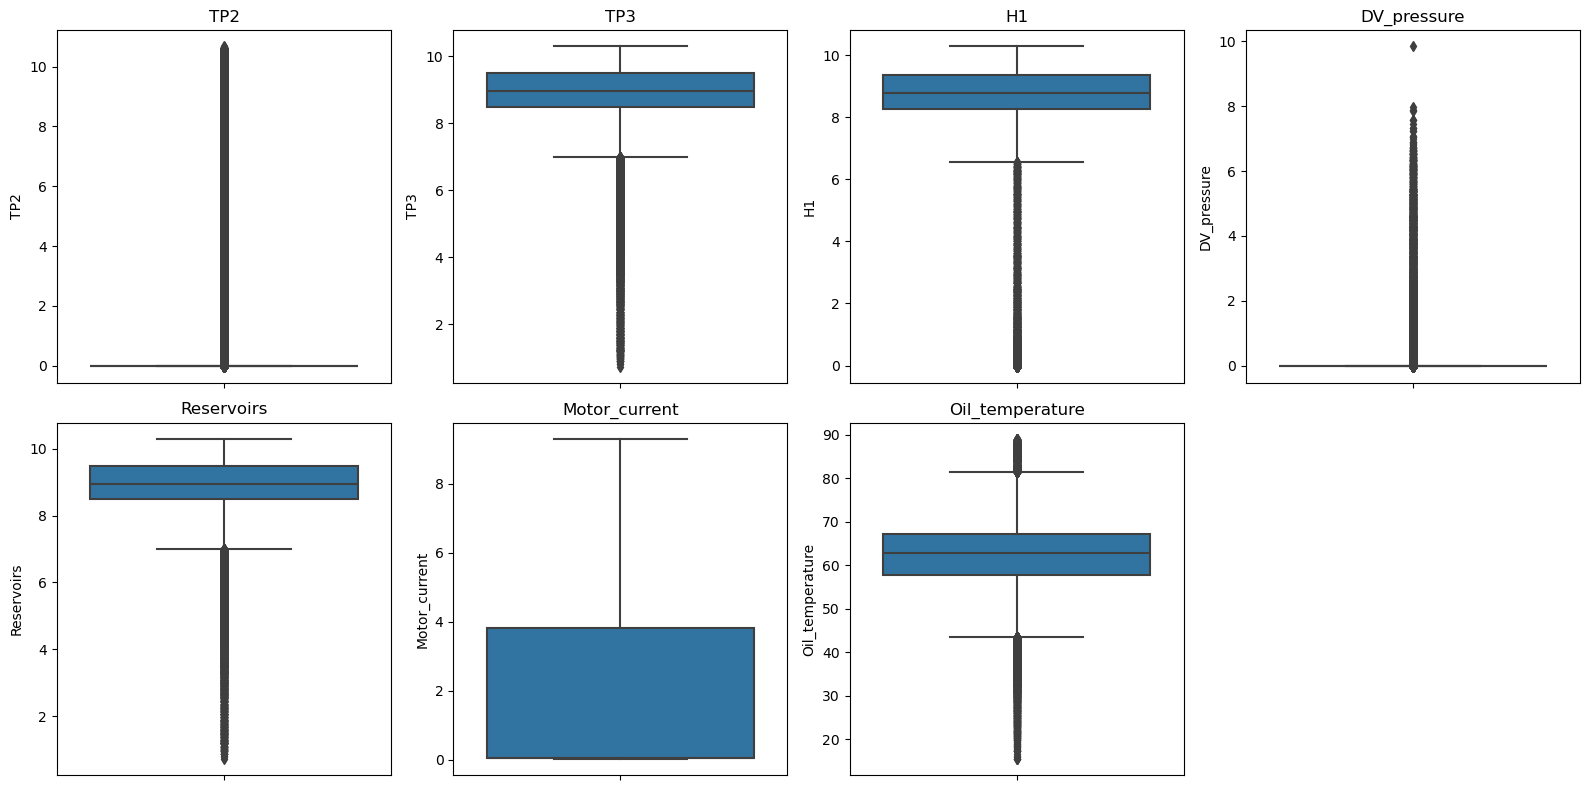

In [14]:
# Boxplot graph to examine each sensor separately
sensor_columns = [
    'TP2', 'TP3', 'H1', 'DV_pressure',
    'Reservoirs', 'Motor_current', 'Oil_temperature'
]

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()

for i, column in enumerate(sensor_columns):
    sns.boxplot(y=df[column], ax=axes[i])
    axes[i].set_title(column)

axes[-1].axis('off')

plt.tight_layout()
plt.show()

The boxplot analysis reveals numerous statistical outliers across several compressor sensor measurements, particularly TP2, TP3, H1, DV_pressure, and Reservoirs. However, these extreme values cannot automatically be classified as abnormal behavior because compressor measurements vary according to operational states, including startup, loaded, unloaded, and inactive conditions.

### Heatmap Correlation

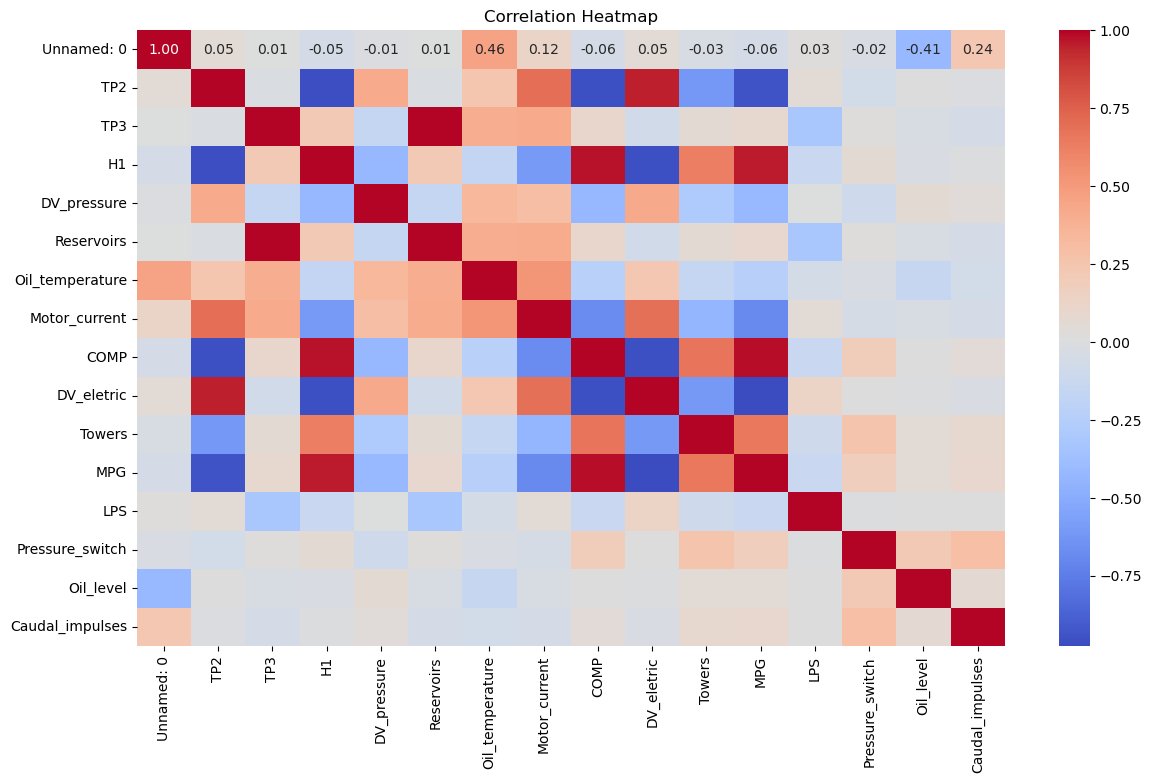

In [15]:
plt.figure(figsize=(14, 8))
corr = df.corr(numeric_only= True)
sns.heatmap(corr, annot= True, cmap='coolwarm', fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

### Motor current overview - Histogram Graph

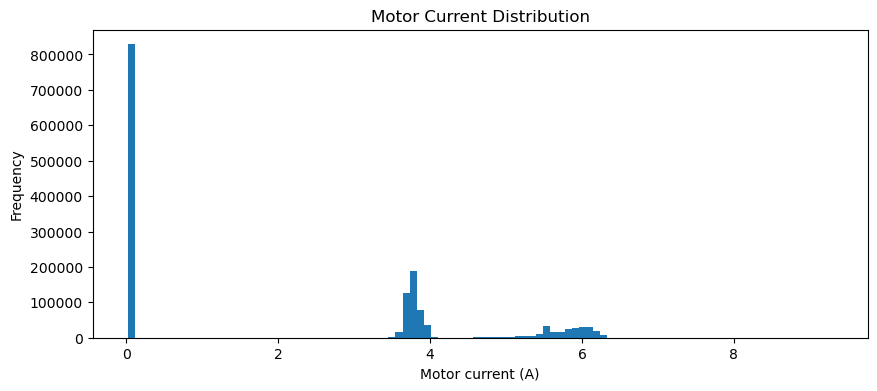

In [16]:
plt.figure(figsize=(10, 4))

plt.hist(df['Motor_current'].dropna(), bins=100)

plt.title('Motor Current Distribution')
plt.xlabel('Motor current (A)')
plt.ylabel('Frequency')
plt.show()

# Data Preparation

## Removing uncessary columns

In [17]:
# Remove the extra CSV index column
df = df.loc[:, ~df.columns.str.startswith('Unnamed:')]

## Creating a motor state column

In [18]:
current = df['Motor_current']

df['motor_state'] = np.select(
    [
        current.between(0, 1, inclusive='left'),
        current.between(1, 5, inclusive='left'),
        current.ge(5)
    ],
    [
        'Off / near zero',
        'Possible unloaded',
        'Possible loaded / startup'
    ],
    default='Unknown'
)

display(df['motor_state'].value_counts())

motor_state
Off / near zero              829000
Possible unloaded            457356
Possible loaded / startup    230592
Name: count, dtype: int64

## Creating the Air-leak failures dataframe

Since the dataset is unlabeled at the sensor-row level but accompanied by external failure-event ground truth provided in the UCI repository, the creation of a dataframe is needed. This dataframe will be useful later for comparing the anomaly alerts generates by our machine learning models against the actual failure periods.
Failure reports: Records of actual air leaks reported by the maintenance team, including their start and end times.

In [19]:
# Creating the dataframe: failure events documented in the MetroPT3 dataset
failure_events = pd.DataFrame({
    'failure_id': [1, 2, 3, 4],
    'start_time': [
        '2020-04-18 00:00:00',
        '2020-05-29 23:30:00',
        '2020-06-05 10:00:00',
        '2020-07-15 14:30:00'
    ],
    'end_time': [
        '2020-04-18 23:59:00',
        '2020-05-30 06:00:00',
        '2020-06-07 14:30:00',
        '2020-07-15 19:00:00'
    ],
    'failure_type': ['Air leak'] * 4,
    'severity': ['High stress'] * 4
})

In [20]:
print(failure_events)

   failure_id           start_time             end_time failure_type  \
0           1  2020-04-18 00:00:00  2020-04-18 23:59:00     Air leak   
1           2  2020-05-29 23:30:00  2020-05-30 06:00:00     Air leak   
2           3  2020-06-05 10:00:00  2020-06-07 14:30:00     Air leak   
3           4  2020-07-15 14:30:00  2020-07-15 19:00:00     Air leak   

      severity  
0  High stress  
1  High stress  
2  High stress  
3  High stress  


In [21]:
failure_events['start_time'] = pd.to_datetime(failure_events['start_time'])
failure_events['end_time'] = pd.to_datetime(failure_events['end_time'])

failure_events.info()

<class 'pandas.DataFrame'>
RangeIndex: 4 entries, 0 to 3
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   failure_id    4 non-null      int64         
 1   start_time    4 non-null      datetime64[us]
 2   end_time      4 non-null      datetime64[us]
 3   failure_type  4 non-null      str           
 4   severity      4 non-null      str           
dtypes: datetime64[us](2), int64(1), str(2)
memory usage: 292.0 bytes


In [22]:
#Calculate failure duration

failure_events['duration_hours'] = (
    failure_events['end_time'] - failure_events['start_time']
).dt.total_seconds() / 3600

display(failure_events)


,failure_id,start_time,end_time,failure_type,severity,duration_hours
0,1,2020-04-18 00:00:00,2020-04-18 23:59:00,Air leak,High stress,23.983333
1,2,2020-05-29 23:30:00,2020-05-30 06:00:00,Air leak,High stress,6.500000
2,3,2020-06-05 10:00:00,2020-06-07 14:30:00,Air leak,High stress,52.500000
3,4,2020-07-15 14:30:00,2020-07-15 19:00:00,Air leak,High stress,4.500000


In [23]:
#Printing the sensor data period & failures period
print("Sensor data period:")
print(df['timestamp'].min(), "to", df['timestamp'].max())

print("\nFailure event period:")
print(
    failure_events['start_time'].min(),
    "to",
    failure_events['end_time'].max()
)


Sensor data period:
2020-02-01 00:00:00 to 2020-09-01 03:59:50

Failure event period:
2020-04-18 00:00:00 to 2020-07-15 19:00:00


## Sensor Behavior and Failure Analysis

### Visualizing sensor behavior over time

In [24]:
#Preparing time-series data
# Work with a copy of the original dataset
ts_df = df.copy()


# Sort chronologically
ts_df = ts_df.sort_values('timestamp')

# Use timestamp as index
ts_df = ts_df.set_index('timestamp')

print("Dataset period:", ts_df.index.min(), "to", ts_df.index.max())
print("Number of observations:", len(ts_df))

display(ts_df.head())

Dataset period: 2020-02-01 00:00:00 to 2020-09-01 03:59:50
Number of observations: 1516948


,TP2,TP3,H1,DV_pressure,Reservoirs,Oil_temperature,Motor_current,COMP,DV_eletric,Towers,MPG,LPS,Pressure_switch,Oil_level,Caudal_impulses,motor_state
timestamp,,,,,,,,,,,,,,,,
2020-02-01 00:00:00,-0.012,9.358,9.340,-0.024,9.358,53.600,0.0400,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0,Off / near zero
2020-02-01 00:00:10,-0.014,9.348,9.332,-0.022,9.348,53.675,0.0400,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0,Off / near zero
2020-02-01 00:00:19,-0.012,9.338,9.322,-0.022,9.338,53.600,0.0425,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0,Off / near zero
2020-02-01 00:00:29,-0.012,9.328,9.312,-0.022,9.328,53.425,0.0400,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0,Off / near zero
2020-02-01 00:00:39,-0.012,9.318,9.302,-0.022,9.318,53.475,0.0400,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0,Off / near zero


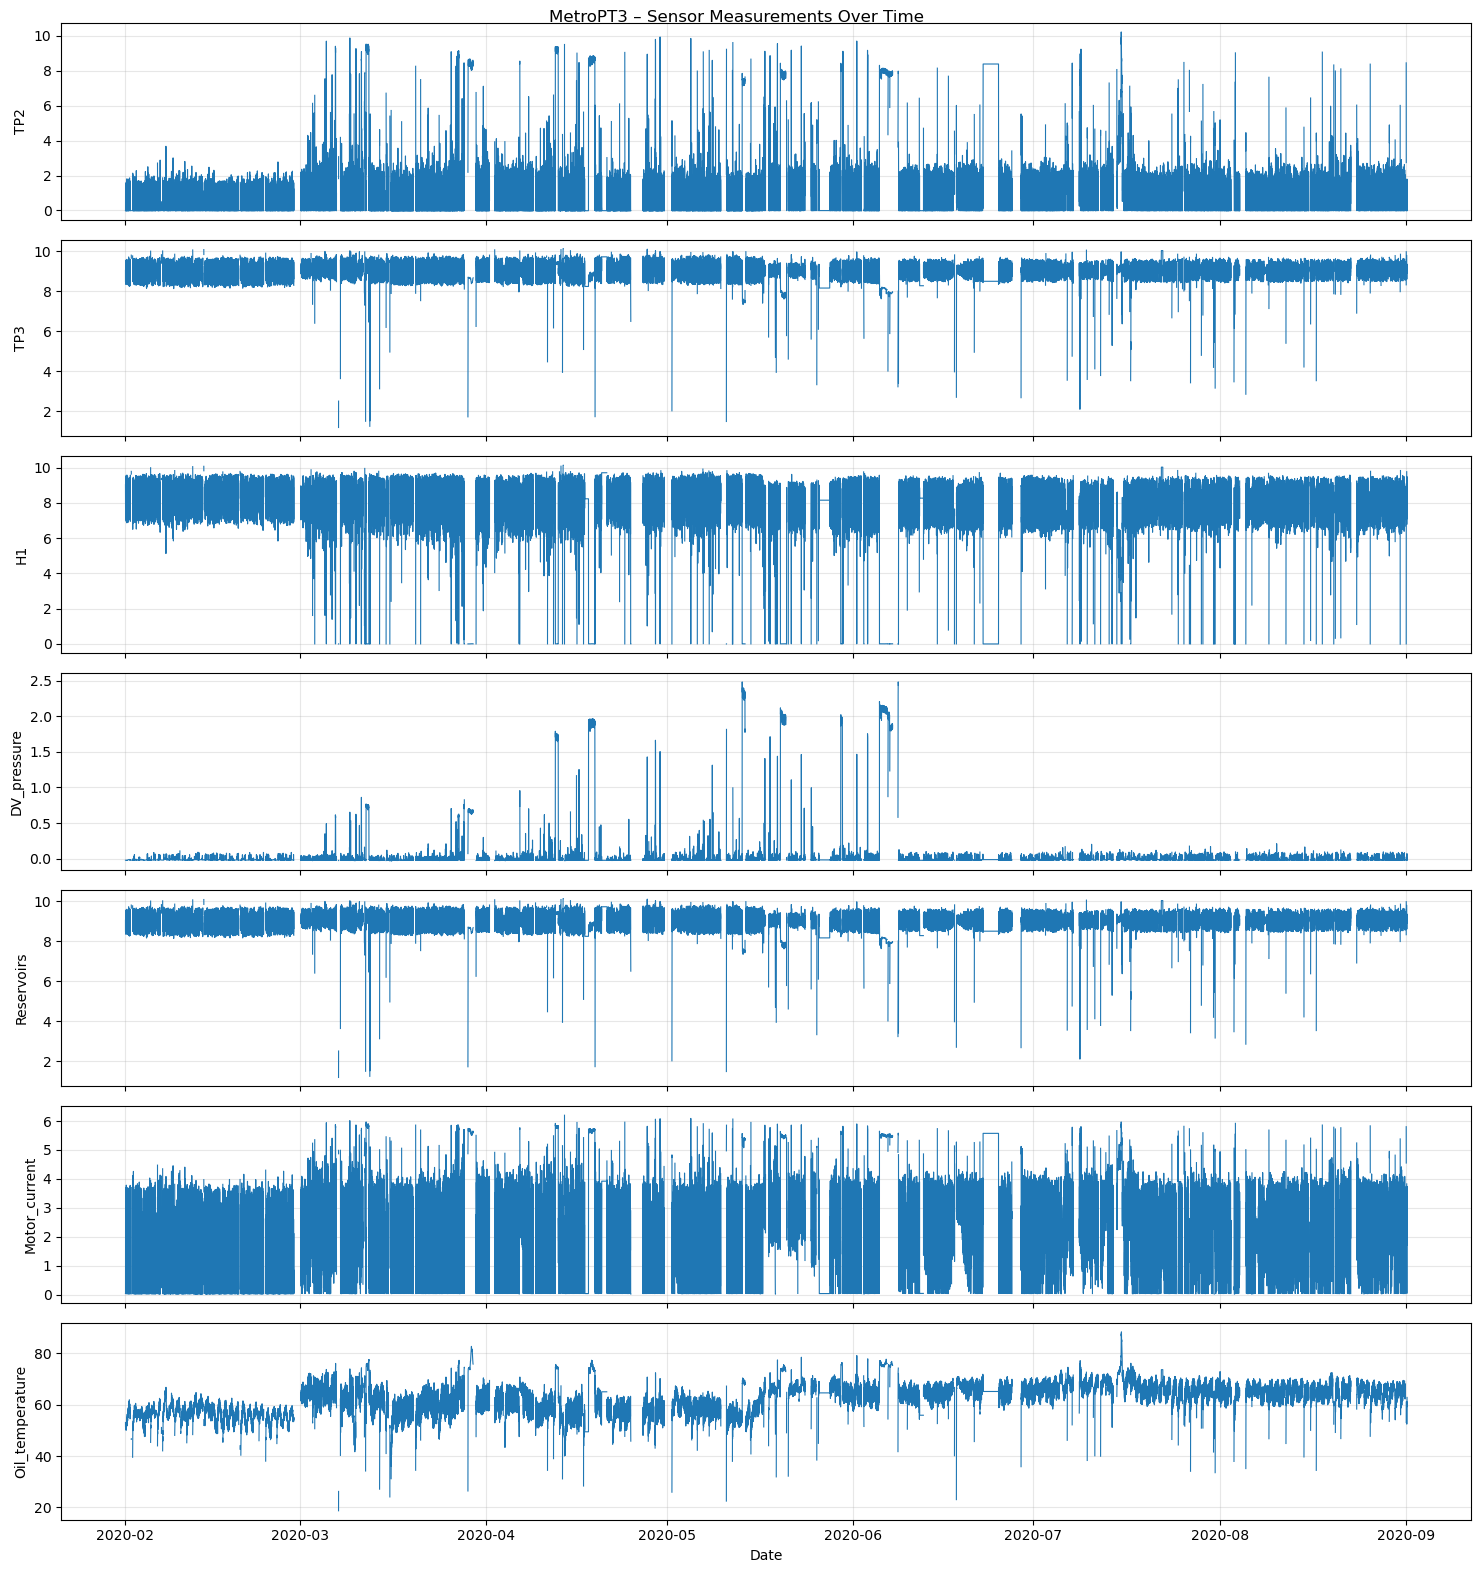

In [25]:

sensor_columns = [
    'TP2',
    'TP3',
    'H1',
    'DV_pressure',
    'Reservoirs',
    'Motor_current',
    'Oil_temperature'
]

# Aggregate sensor readings into 10-minute intervals
ts_10min = ts_df[sensor_columns].resample('10min').mean()

fig, axes = plt.subplots(
    len(sensor_columns), 1,
    figsize=(15, 16),
    sharex=True
)

for ax, sensor in zip(axes, sensor_columns):
    ax.plot(ts_10min.index, ts_10min[sensor], linewidth=0.8)
    ax.set_ylabel(sensor)
    ax.grid(alpha=0.3)

axes[-1].set_xlabel('Date')
fig.suptitle('MetroPT3 – Sensor Measurements Over Time')

plt.tight_layout()
plt.show()

### Analyzing the periods before a documented failure

In order to investigate the sensor behavior within the sensor signals, the investigation was divided between three groups:

- Group 1: Pressure and airflow
- Group 2: Compressor Operation
- Group 3: Temperature, Dryers and Safety



In [26]:
sensor_groups = {
    'Pressure and Airflow': [
        'TP2', 'TP3', 'H1', 'DV_pressure',
        'Reservoirs', 'Caudal_impulses'
    ],

    'Compressor Operation': [
        'Motor_current', 'COMP', 'DV_eletric', 'MPG'
    ],

    'Temperature, Dryers and Safety': [
        'Oil_temperature', 'Towers', 'LPS',
        'Pressure_switch', 'Oil_level'
    ]
}

print(sensor_groups)

{'Pressure and Airflow': ['TP2', 'TP3', 'H1', 'DV_pressure', 'Reservoirs', 'Caudal_impulses'], 'Compressor Operation': ['Motor_current', 'COMP', 'DV_eletric', 'MPG'], 'Temperature, Dryers and Safety': ['Oil_temperature', 'Towers', 'LPS', 'Pressure_switch', 'Oil_level']}


#### Identifying pattern Failure 1

##### Sensor analysis group 1: Pressure and Airflow

In [27]:

def plot_failure_window(
    ts_df,
    failure_events,
    failure_id,
    hours_before=48,
    hours_after=6,
    sensors=None
):
    if sensors is None:
        sensors = sensor_groups['Pressure and Airflow']

    event = failure_events.loc[
        failure_events['failure_id'] == failure_id
    ].iloc[0]

    failure_start = event['start_time']
    failure_end = event['end_time']

    window_start = failure_start - pd.Timedelta(hours=hours_before)
    window_end = failure_end + pd.Timedelta(hours=hours_after)

    subset = ts_df.loc[window_start:window_end, sensors]

    # 1-minute medians for a readable overview
    subset_plot = subset.resample('1min').median()

    fig, axes = plt.subplots(
        len(sensors), 1,
        figsize=(15, 3 * len(sensors)),
        sharex=True,
        squeeze=False
    )

    for ax, sensor in zip(axes.flat, sensors):
        ax.plot(
            subset_plot.index,
            subset_plot[sensor],
            linewidth=0.9,
            label=sensor
        )

        ax.axvspan(
            failure_start,
            failure_end,
            color='red',
            alpha=0.15,
            label='Reported failure period'
        )

        ax.axvline(
            failure_start,
            color='red',
            linestyle='--',
            label='Failure start'
        )

        ax.set_ylabel(sensor)
        ax.legend(loc='upper right')
        ax.grid(alpha=0.3)

    axes[-1, 0].set_xlabel('Timestamp')
    fig.suptitle(f'MetroPT3 – Failure {failure_id}')
    plt.tight_layout()
    plt.show()


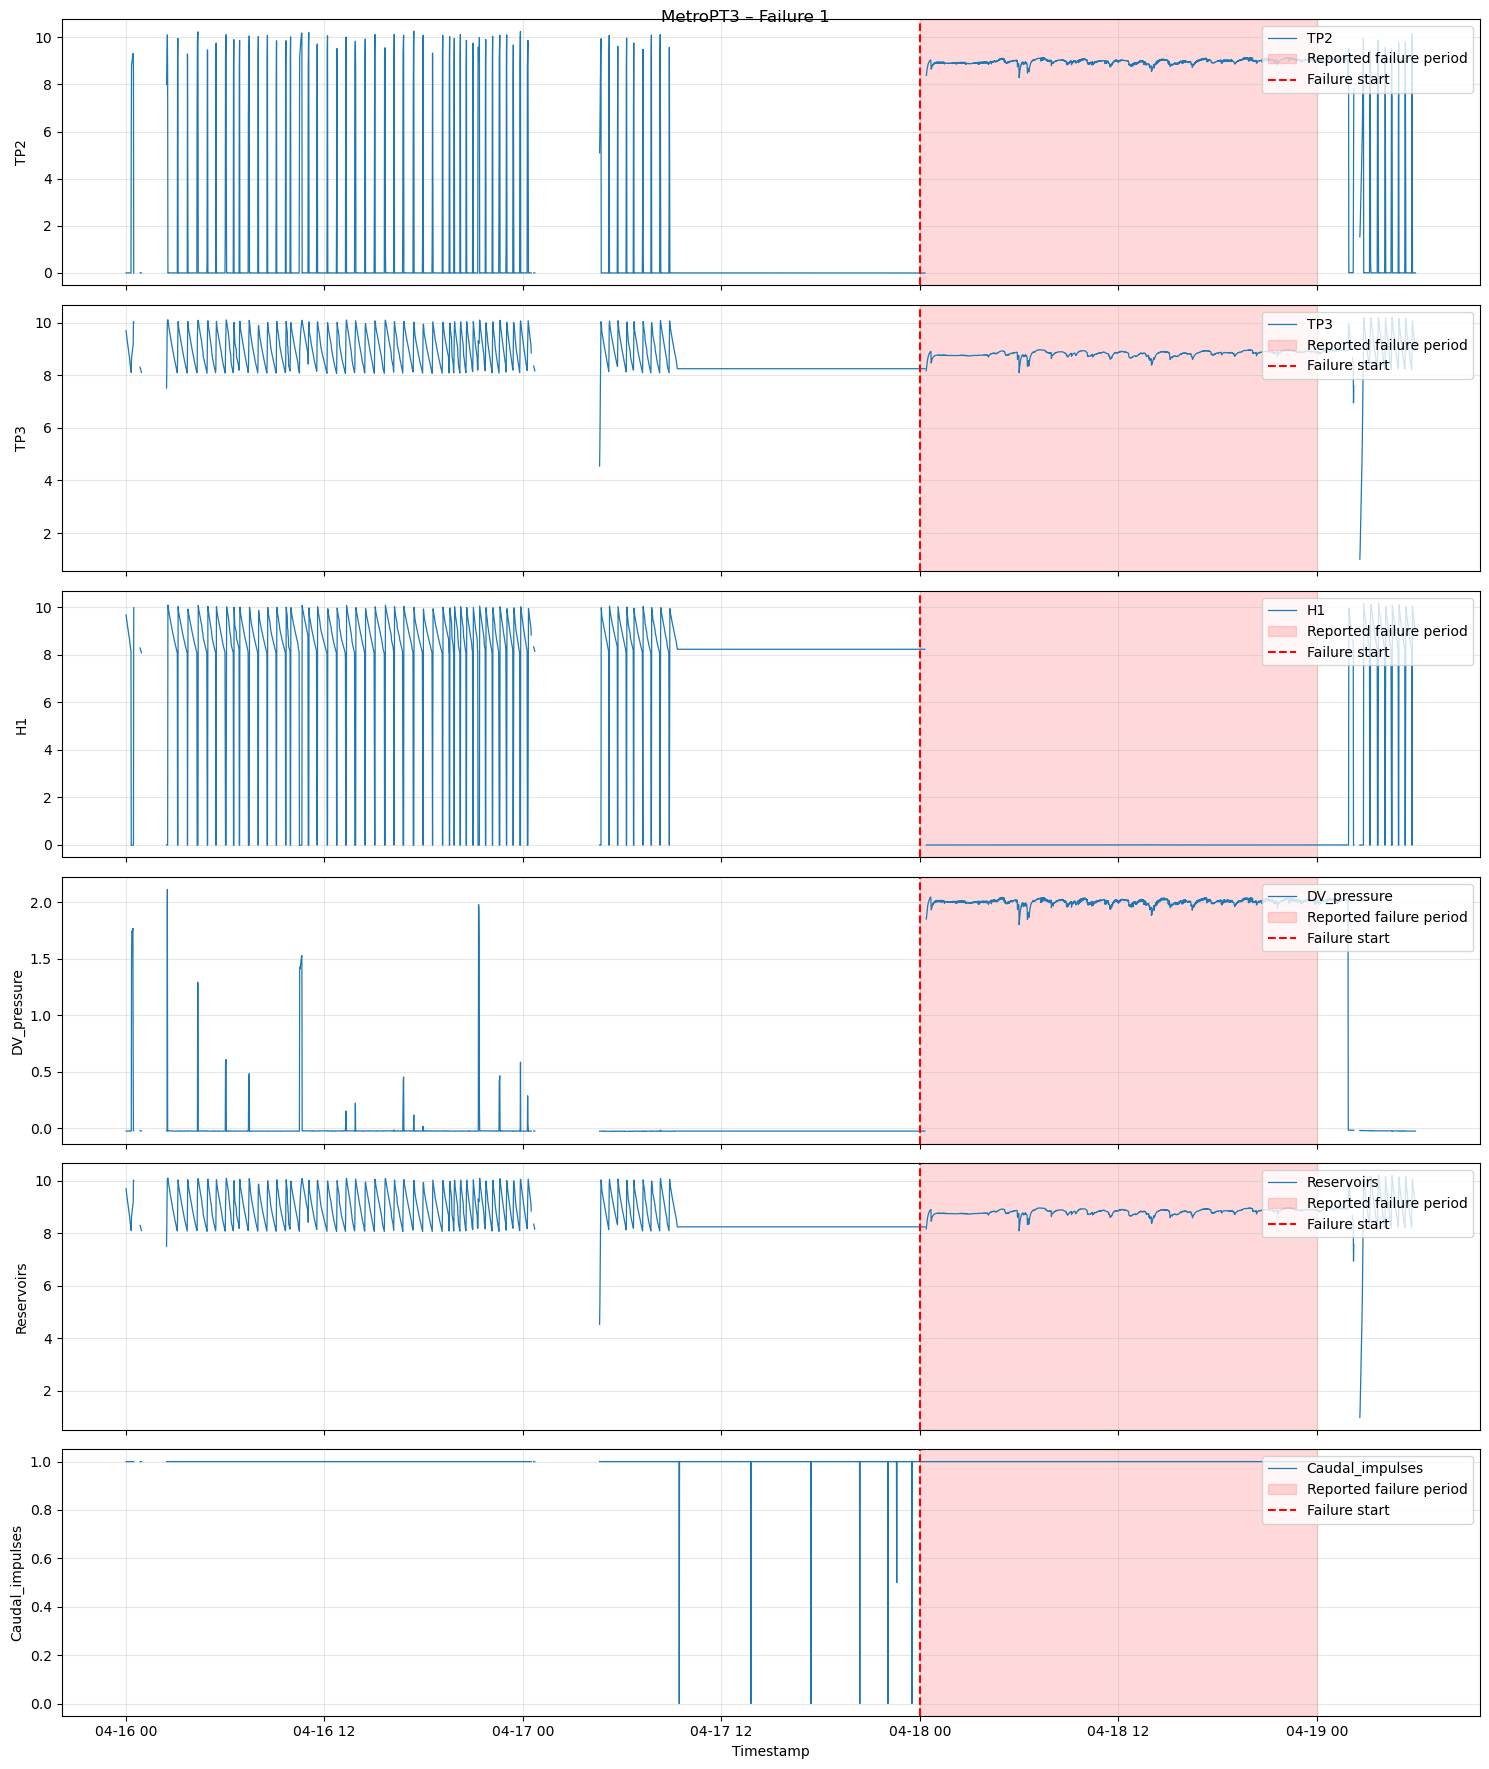

In [28]:
plot_failure_window(
    ts_df,
    failure_events,
    failure_id=1,
    hours_before=48,
    hours_after=6
)

##### Sensor analysis group 2: Compressor Operation

In [29]:

def plot_failure_window(
    ts_df,
    failure_events,
    failure_id,
    hours_before=48,
    hours_after=6,
    sensors=None
):
    if sensors is None:
        sensors = sensor_groups['Compressor Operation']

    event = failure_events.loc[
        failure_events['failure_id'] == failure_id
    ].iloc[0]

    failure_start = event['start_time']
    failure_end = event['end_time']

    window_start = failure_start - pd.Timedelta(hours=hours_before)
    window_end = failure_end + pd.Timedelta(hours=hours_after)

    subset = ts_df.loc[window_start:window_end, sensors]

    # 1-minute medians for a readable overview
    subset_plot = subset.resample('1min').median()

    fig, axes = plt.subplots(
        len(sensors), 1,
        figsize=(15, 3 * len(sensors)),
        sharex=True,
        squeeze=False
    )

    for ax, sensor in zip(axes.flat, sensors):
        ax.plot(
            subset_plot.index,
            subset_plot[sensor],
            linewidth=0.9,
            label=sensor
        )

        ax.axvspan(
            failure_start,
            failure_end,
            color='red',
            alpha=0.15,
            label='Reported failure period'
        )

        ax.axvline(
            failure_start,
            color='red',
            linestyle='--',
            label='Failure start'
        )

        ax.set_ylabel(sensor)
        ax.legend(loc='upper right')
        ax.grid(alpha=0.3)

    axes[-1, 0].set_xlabel('Timestamp')
    fig.suptitle(f'MetroPT3 – Failure {failure_id}')
    plt.tight_layout()
    plt.show()


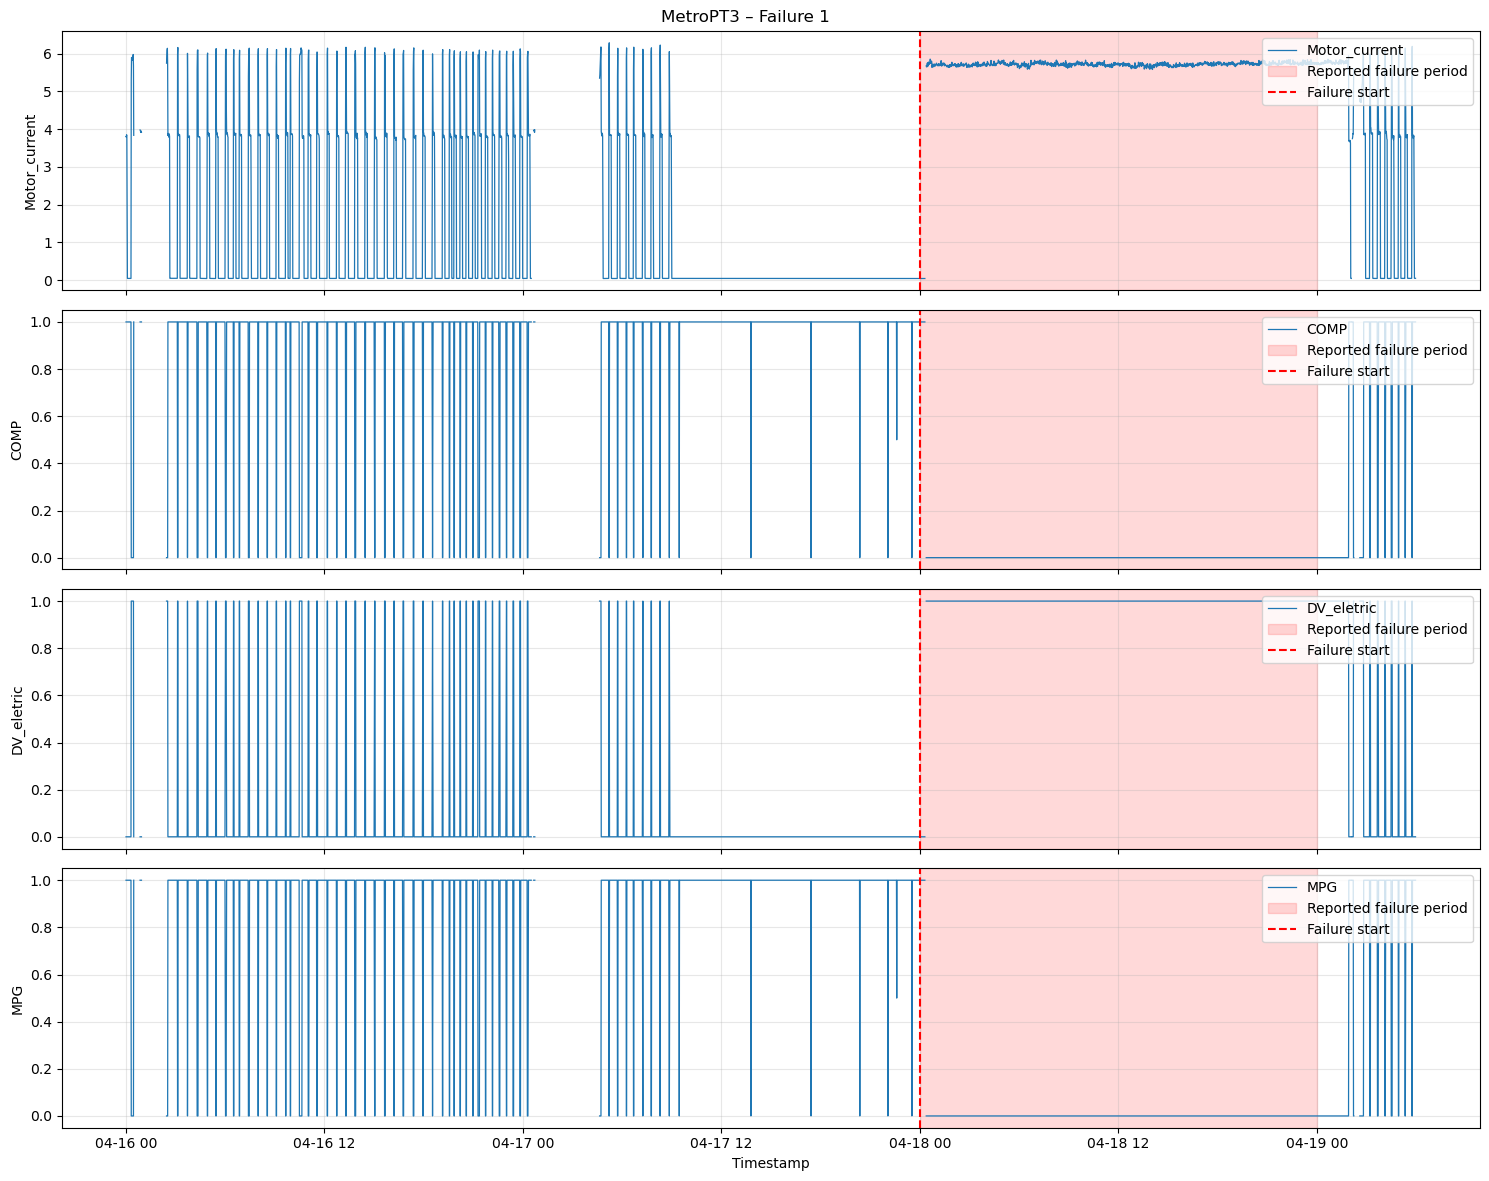

In [30]:
plot_failure_window(
    ts_df,
    failure_events,
    failure_id=1,
    hours_before=48,
    hours_after=6
)

##### Sensor analysis group 3: Temperature, Dryers and Safety

In [31]:
def plot_failure_window(
    ts_df,
    failure_events,
    failure_id,
    hours_before=48,
    hours_after=6,
    sensors=None
):
    if sensors is None:
        sensors = sensor_groups['Temperature, Dryers and Safety']

    event = failure_events.loc[
        failure_events['failure_id'] == failure_id
    ].iloc[0]

    failure_start = event['start_time']
    failure_end = event['end_time']

    window_start = failure_start - pd.Timedelta(hours=hours_before)
    window_end = failure_end + pd.Timedelta(hours=hours_after)

    subset = ts_df.loc[window_start:window_end, sensors]

    # 1-minute medians for a readable overview
    subset_plot = subset.resample('1min').median()

    fig, axes = plt.subplots(
        len(sensors), 1,
        figsize=(15, 3 * len(sensors)),
        sharex=True,
        squeeze=False
    )

    for ax, sensor in zip(axes.flat, sensors):
        ax.plot(
            subset_plot.index,
            subset_plot[sensor],
            linewidth=0.9,
            label=sensor
        )

        ax.axvspan(
            failure_start,
            failure_end,
            color='red',
            alpha=0.15,
            label='Reported failure period'
        )

        ax.axvline(
            failure_start,
            color='red',
            linestyle='--',
            label='Failure start'
        )

        ax.set_ylabel(sensor)
        ax.legend(loc='upper right')
        ax.grid(alpha=0.3)

    axes[-1, 0].set_xlabel('Timestamp')
    fig.suptitle(f'MetroPT3 – Failure {failure_id}')
    plt.tight_layout()
    plt.show()


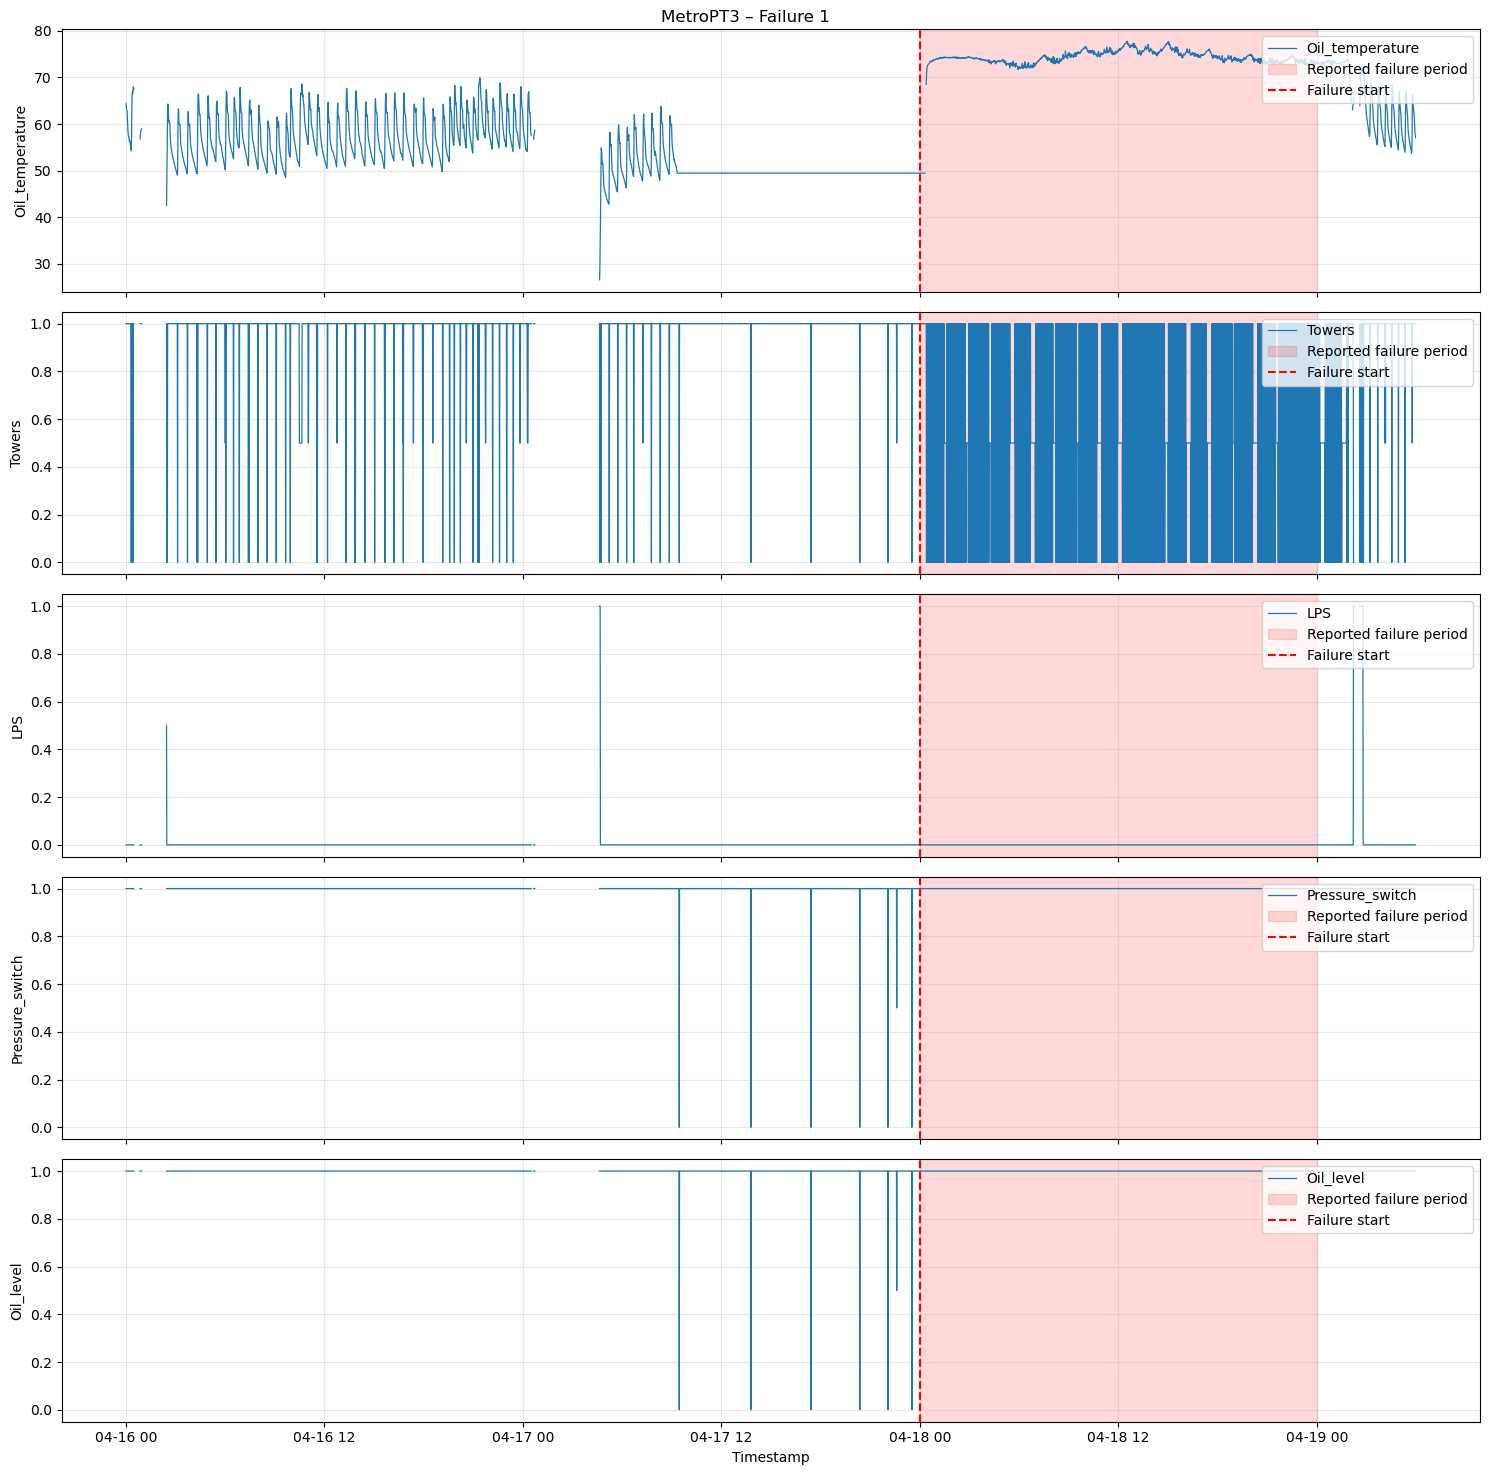

In [32]:
plot_failure_window(
    ts_df,
    failure_events,
    failure_id=1,
    hours_before=48,
    hours_after=6
)

#### Examining sensor behavior across three periods

In [33]:

event = failure_events.loc[
    failure_events['failure_id'] == 1
].iloc[0]

t = event['start_time']

# Define periods without overlapping timestamps
periods = {
    '48–24h before': ts_df.loc[
        (ts_df.index >= t - pd.Timedelta(hours=48)) &
        (ts_df.index < t - pd.Timedelta(hours=24))
    ],
    '24–0h before': ts_df.loc[
        (ts_df.index >= t - pd.Timedelta(hours=24)) &
        (ts_df.index < t)
    ],
    'During failure': ts_df.loc[
        (ts_df.index >= t) &
        (ts_df.index <= event['end_time'])
    ]
}

# Get all sensors from the existing sensor_groups dictionary
all_sensors = [
    sensor
    for sensors in sensor_groups.values()
    for sensor in sensors
]

# Calculate mean for each sensor in each period
results = []

for name, data in periods.items():
    row = {'Period': name}

    for sensor in all_sensors:
        row[sensor] = data[sensor].mean()

    results.append(row)

comparison = pd.DataFrame(results).set_index('Period')

display(comparison.round(2))

,TP2,TP3,H1,DV_pressure,Reservoirs,Caudal_impulses,Motor_current,COMP,DV_eletric,MPG,Oil_temperature,Towers,LPS,Pressure_switch,Oil_level
Period,,,,,,,,,,,,,,,
48–24h before,0.85,9.01,8.11,0.01,9.01,1.00,1.49,0.90,0.10,0.90,57.31,0.95,0.0,1.00,1.00
24–0h before,0.19,8.47,8.25,-0.02,8.47,0.86,0.45,0.83,0.02,0.83,50.45,0.85,0.0,0.86,0.86
During failure,8.52,8.81,0.08,1.88,8.81,1.00,5.60,0.01,0.99,0.01,74.13,0.50,0.0,0.99,1.00


#### Conclusion Failure 1

- **During the failure** the compressor stays in continuous loaded operation for the whole reported window: Motor_current is flat at about 5.6 A, COMP and MPG drop to 0, DV_eletric stays at 1, TP2 rises to about 8.5 bar, H1 falls to about 0 and Oil_temperature rises to about 74 °C. Towers averages 0.5, meaning both drying towers alternate.
- **Before the failure** no gradual degradation is visible. The compressor cycles normally on 16 April and then stays idle (Motor_current close to 0) from about 09:00 on 17 April until the failure starts abruptly at 00:00 on 18 April. The lower 24–0h means (Motor_current 0.45 A, Oil_temperature 50 °C) reflect this idle period and do not indicate a fault.
- There is a data gap in the early hours of 17 April.
- **Early-warning potential:** low at this resolution. The failure appears as a sudden switch to continuous load.

#### Identifying pattern Failure 2

##### Sensor analysis group 1: Pressure and Airflow

In [34]:
def plot_failure_window(
    ts_df,
    failure_events,
    failure_id,
    hours_before=48,
    hours_after=6,
    sensors=None
):
    if sensors is None:
        sensors = sensor_groups['Pressure and Airflow']

    event = failure_events.loc[
        failure_events['failure_id'] == failure_id
    ].iloc[0]

    failure_start = event['start_time']
    failure_end = event['end_time']

    window_start = failure_start - pd.Timedelta(hours=hours_before)
    window_end = failure_end + pd.Timedelta(hours=hours_after)

    subset = ts_df.loc[window_start:window_end, sensors]

    # 1-minute medians for a readable overview
    subset_plot = subset.resample('1min').median()

    fig, axes = plt.subplots(
        len(sensors), 1,
        figsize=(15, 3 * len(sensors)),
        sharex=True,
        squeeze=False
    )

    for ax, sensor in zip(axes.flat, sensors):
        ax.plot(
            subset_plot.index,
            subset_plot[sensor],
            linewidth=0.9,
            label=sensor
        )

        ax.axvspan(
            failure_start,
            failure_end,
            color='red',
            alpha=0.15,
            label='Reported failure period'
        )

        ax.axvline(
            failure_start,
            color='red',
            linestyle='--',
            label='Failure start'
        )

        ax.set_ylabel(sensor)
        ax.legend(loc='upper right')
        ax.grid(alpha=0.3)

    axes[-1, 0].set_xlabel('Timestamp')
    fig.suptitle(f'MetroPT3 – Failure {failure_id}')
    plt.tight_layout()
    plt.show()

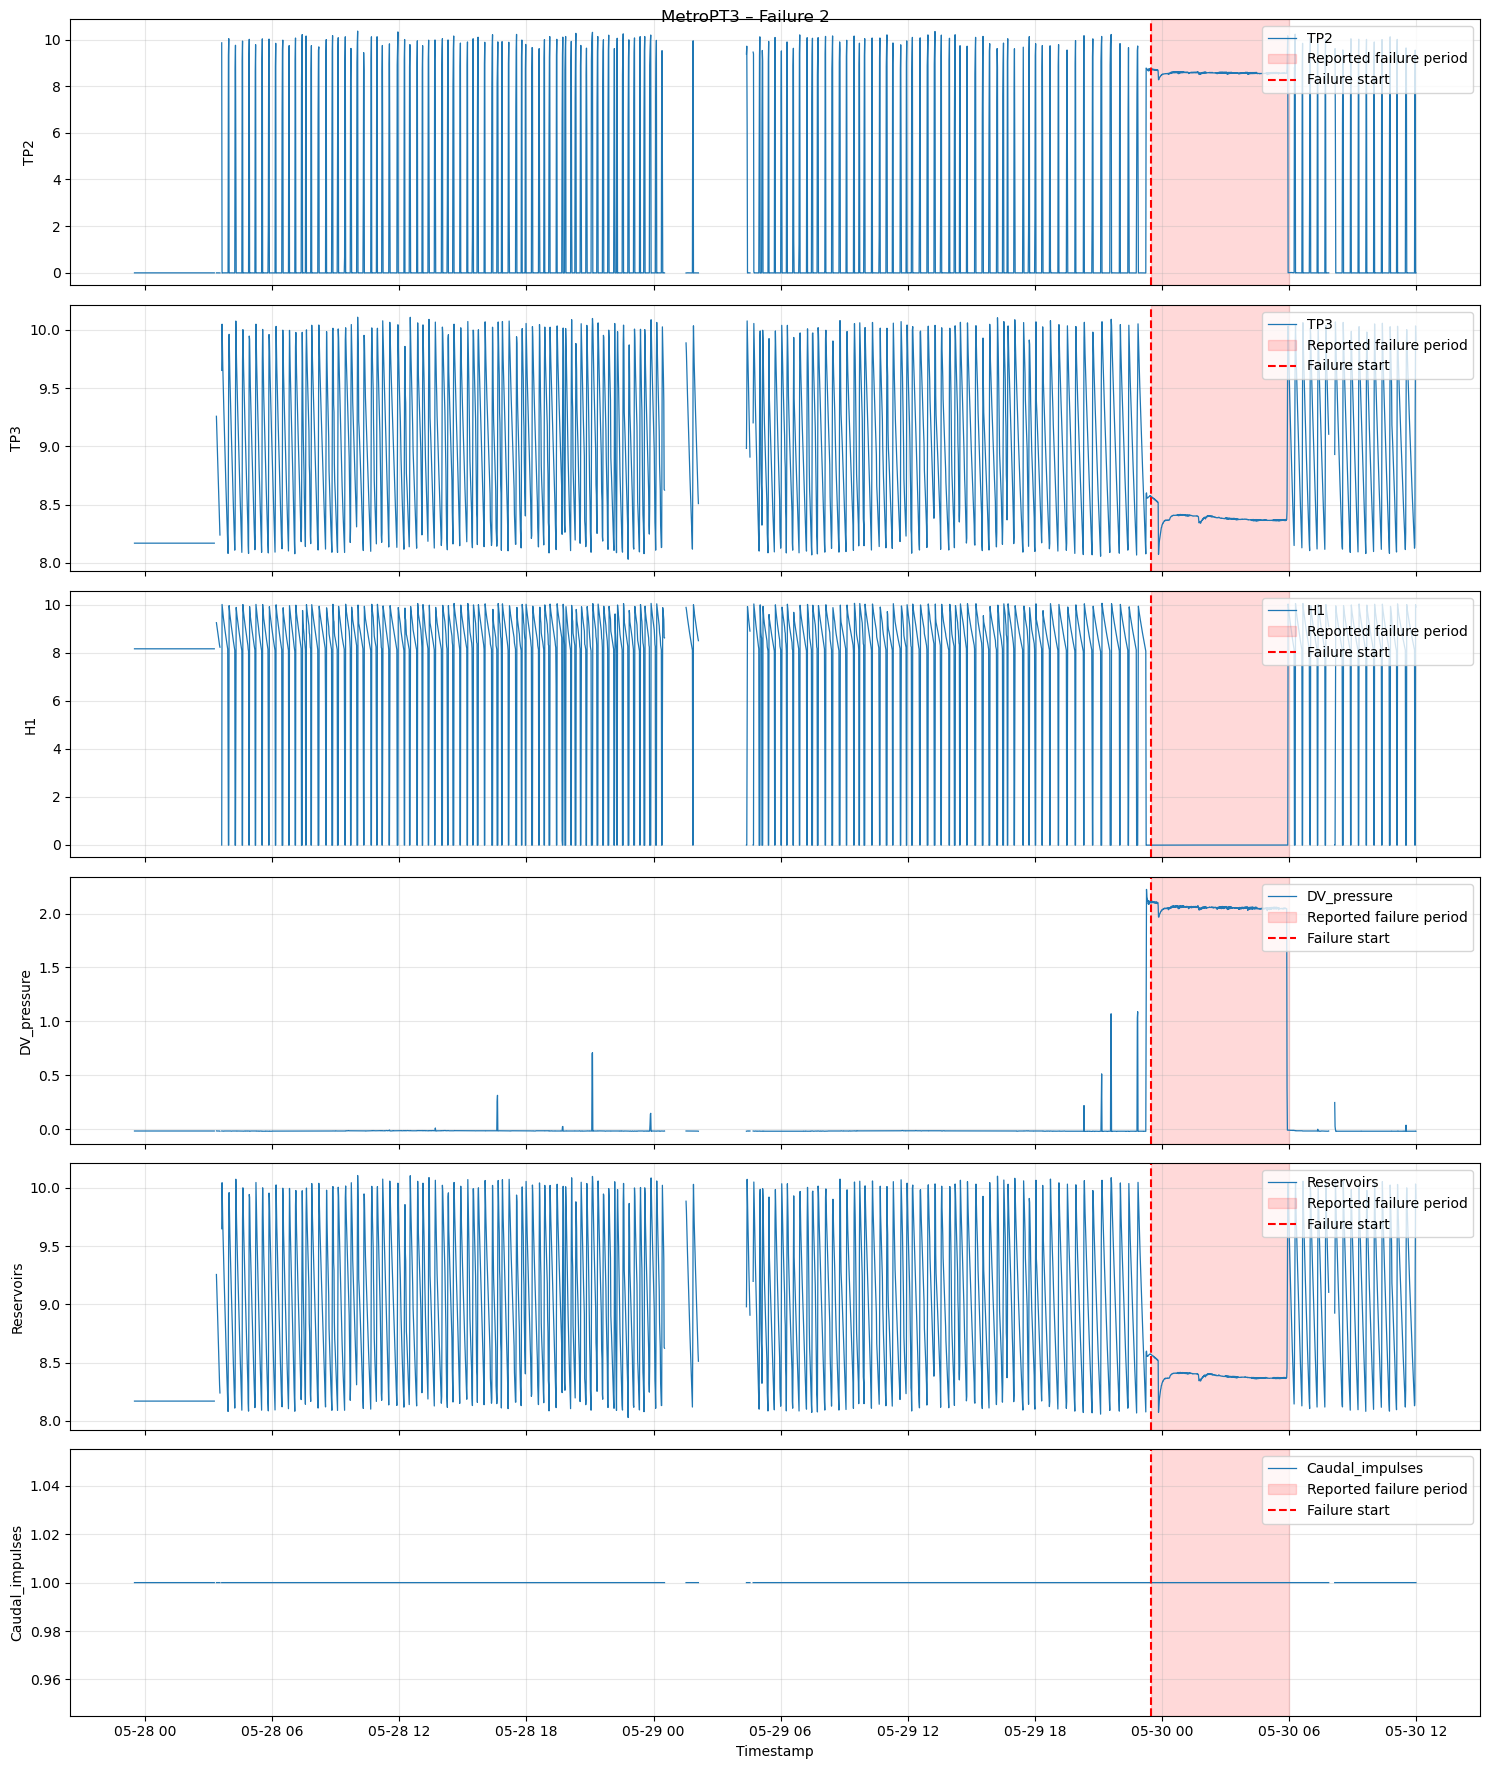

In [35]:
plot_failure_window(
    ts_df,
    failure_events,
    failure_id=2,
    hours_before=48,
    hours_after=6
)

##### Sensor analysis group 2: Compressor Operation

In [36]:
def plot_failure_window(
    ts_df,
    failure_events,
    failure_id,
    hours_before=48,
    hours_after=6,
    sensors=None
):
    if sensors is None:
        sensors = sensor_groups['Compressor Operation']

    event = failure_events.loc[
        failure_events['failure_id'] == failure_id
    ].iloc[0]

    failure_start = event['start_time']
    failure_end = event['end_time']

    window_start = failure_start - pd.Timedelta(hours=hours_before)
    window_end = failure_end + pd.Timedelta(hours=hours_after)

    subset = ts_df.loc[window_start:window_end, sensors]

    # 1-minute medians for a readable overview
    subset_plot = subset.resample('1min').median()

    fig, axes = plt.subplots(
        len(sensors), 1,
        figsize=(15, 3 * len(sensors)),
        sharex=True,
        squeeze=False
    )

    for ax, sensor in zip(axes.flat, sensors):
        ax.plot(
            subset_plot.index,
            subset_plot[sensor],
            linewidth=0.9,
            label=sensor
        )

        ax.axvspan(
            failure_start,
            failure_end,
            color='red',
            alpha=0.15,
            label='Reported failure period'
        )

        ax.axvline(
            failure_start,
            color='red',
            linestyle='--',
            label='Failure start'
        )

        ax.set_ylabel(sensor)
        ax.legend(loc='upper right')
        ax.grid(alpha=0.3)

    axes[-1, 0].set_xlabel('Timestamp')
    fig.suptitle(f'MetroPT3 – Failure {failure_id}')
    plt.tight_layout()
    plt.show()

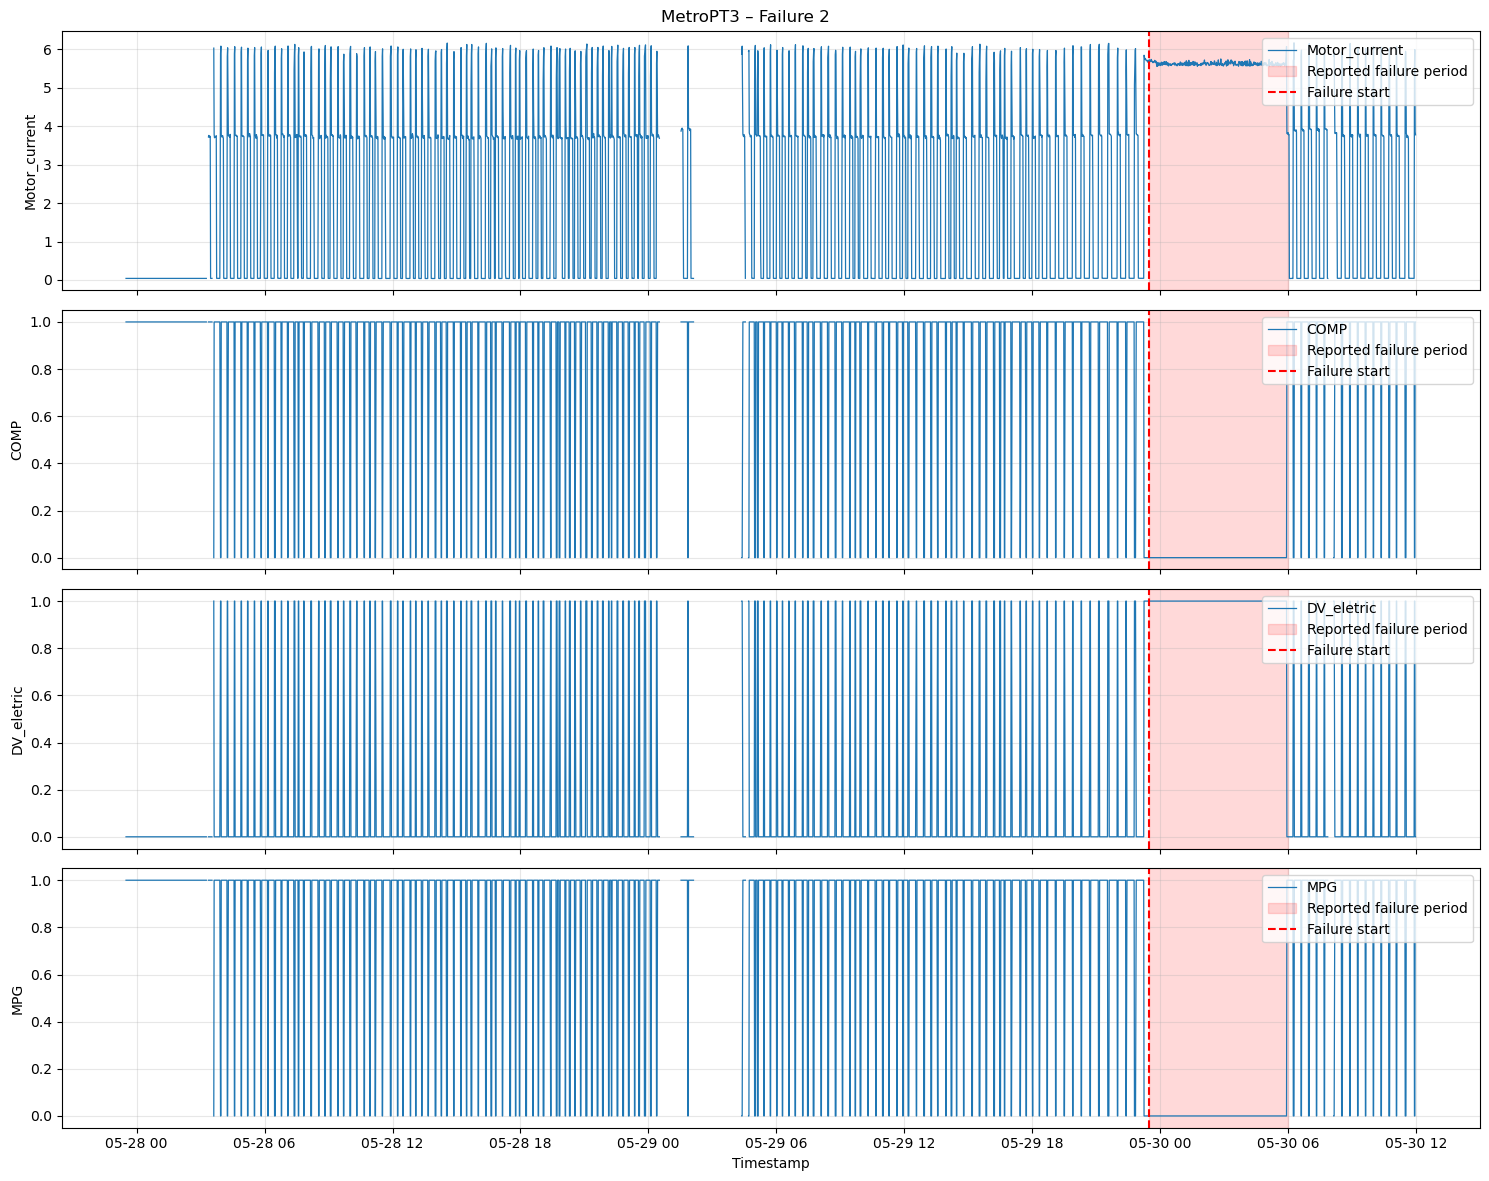

In [37]:
plot_failure_window(
    ts_df,
    failure_events,
    failure_id=2,
    hours_before=48,
    hours_after=6
)

##### Sensor analysis group 3: Temperature, Dryers and Safety

In [38]:
def plot_failure_window(
    ts_df,
    failure_events,
    failure_id,
    hours_before=48,
    hours_after=6,
    sensors=None
):
    if sensors is None:
        sensors = sensor_groups['Temperature, Dryers and Safety']

    event = failure_events.loc[
        failure_events['failure_id'] == failure_id
    ].iloc[0]

    failure_start = event['start_time']
    failure_end = event['end_time']

    window_start = failure_start - pd.Timedelta(hours=hours_before)
    window_end = failure_end + pd.Timedelta(hours=hours_after)

    subset = ts_df.loc[window_start:window_end, sensors]

    # 1-minute medians for a readable overview
    subset_plot = subset.resample('1min').median()

    fig, axes = plt.subplots(
        len(sensors), 1,
        figsize=(15, 3 * len(sensors)),
        sharex=True,
        squeeze=False
    )

    for ax, sensor in zip(axes.flat, sensors):
        ax.plot(
            subset_plot.index,
            subset_plot[sensor],
            linewidth=0.9,
            label=sensor
        )

        ax.axvspan(
            failure_start,
            failure_end,
            color='red',
            alpha=0.15,
            label='Reported failure period'
        )

        ax.axvline(
            failure_start,
            color='red',
            linestyle='--',
            label='Failure start'
        )

        ax.set_ylabel(sensor)
        ax.legend(loc='upper right')
        ax.grid(alpha=0.3)

    axes[-1, 0].set_xlabel('Timestamp')
    fig.suptitle(f'MetroPT3 – Failure {failure_id}')
    plt.tight_layout()
    plt.show()

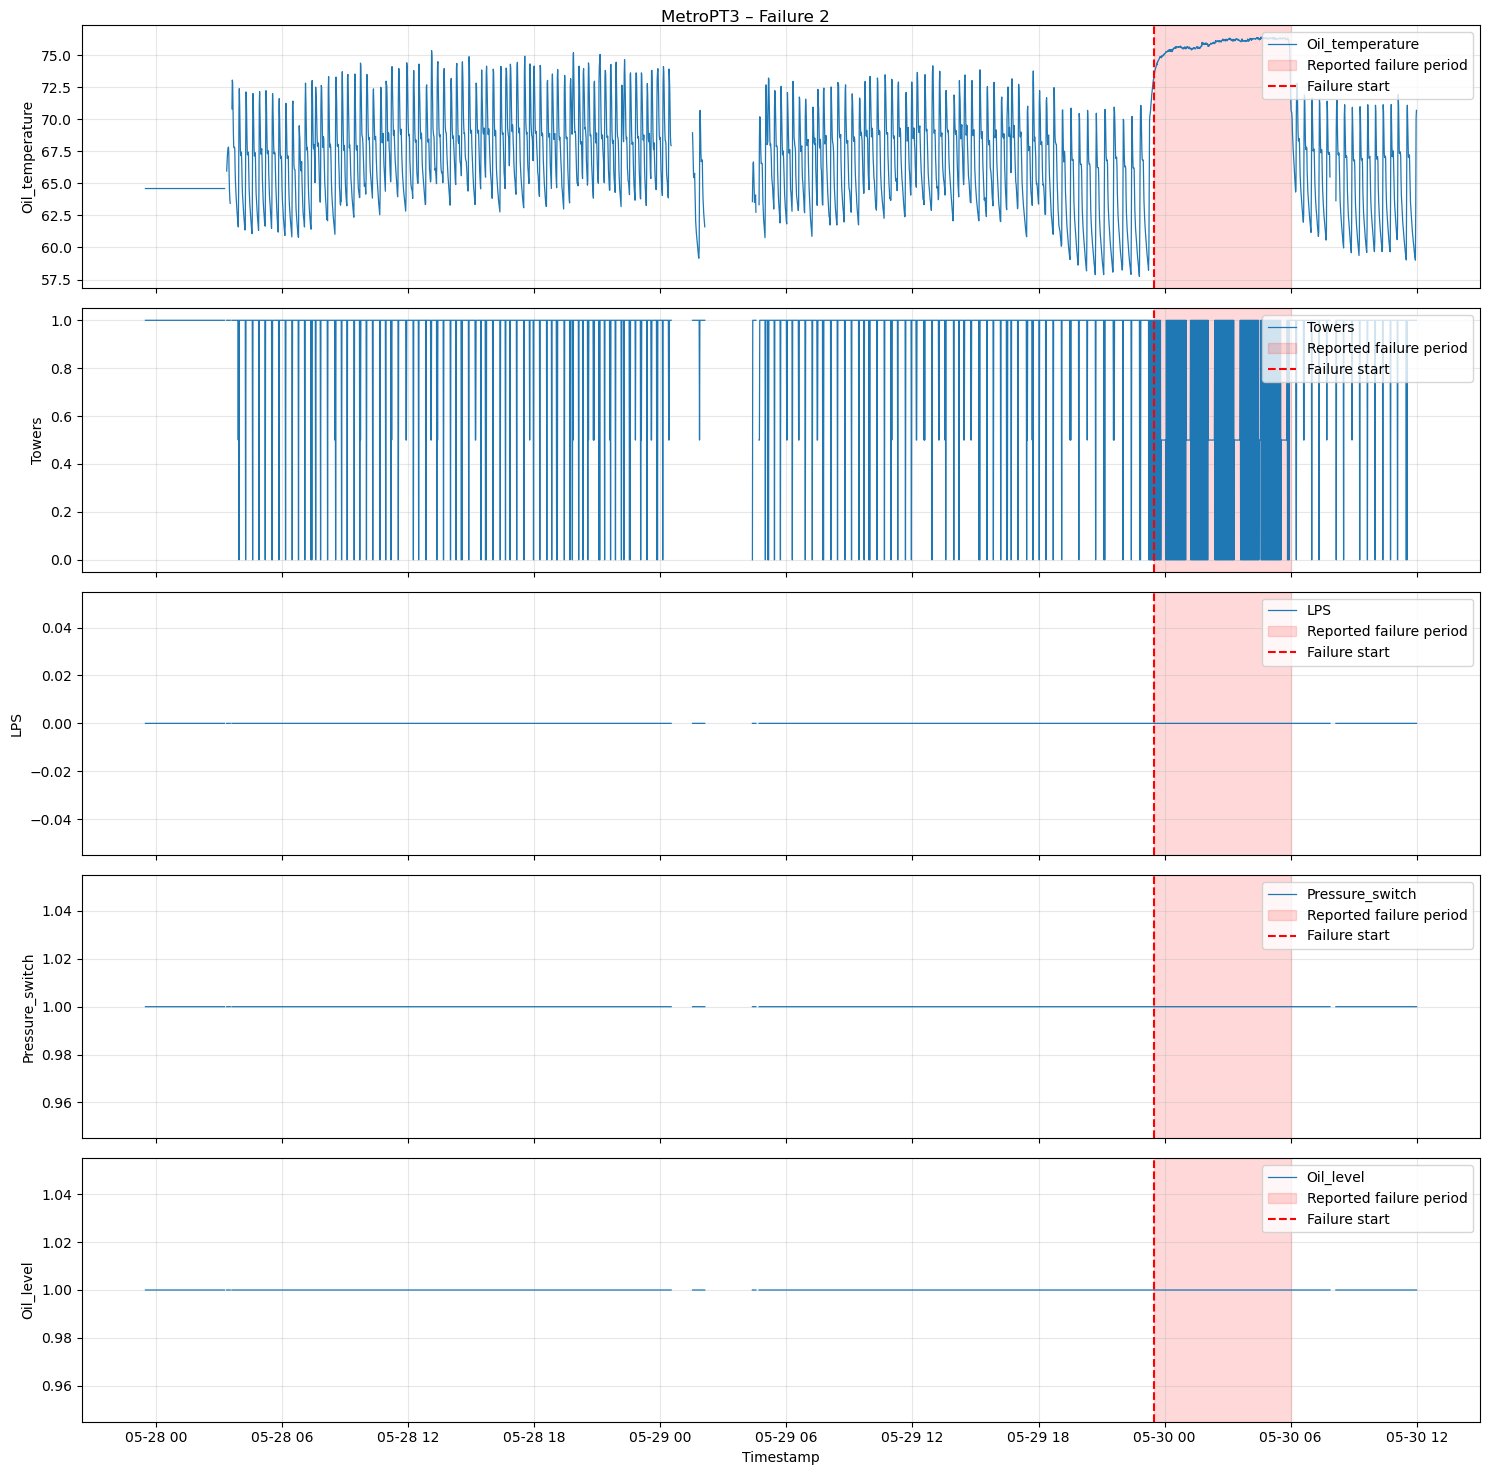

In [39]:
plot_failure_window(
    ts_df,
    failure_events,
    failure_id=2,
    hours_before=48,
    hours_after=6
)

#### Examining sensor behavior across three periods

In [40]:
event = failure_events.loc[
    failure_events['failure_id'] == 2
].iloc[0]

t = event['start_time']

# Define periods without overlapping timestamps
periods = {
    '48–24h before': ts_df.loc[
        (ts_df.index >= t - pd.Timedelta(hours=48)) &
        (ts_df.index < t - pd.Timedelta(hours=24))
    ],
    '24–0h before': ts_df.loc[
        (ts_df.index >= t - pd.Timedelta(hours=24)) &
        (ts_df.index < t)
    ],
    'During failure': ts_df.loc[
        (ts_df.index >= t) &
        (ts_df.index <= event['end_time'])
    ]
}

# Get all sensors from the existing sensor_groups dictionary
all_sensors = [
    sensor
    for sensors in sensor_groups.values()
    for sensor in sensors
]

# Calculate mean for each sensor in each period
results = []

for name, data in periods.items():
    row = {'Period': name}

    for sensor in all_sensors:
        row[sensor] = data[sensor].mean()

    results.append(row)

comparison = pd.DataFrame(results).set_index('Period')

display(comparison.round(2))

,TP2,TP3,H1,DV_pressure,Reservoirs,Caudal_impulses,Motor_current,COMP,DV_eletric,MPG,Oil_temperature,Towers,LPS,Pressure_switch,Oil_level
Period,,,,,,,,,,,,,,,
48–24h before,1.12,8.92,7.77,-0.01,8.92,0.97,2.04,0.85,0.12,0.85,67.27,0.91,0.0,0.97,0.97
24–0h before,1.24,9.02,7.75,0.01,9.02,1.00,2.13,0.86,0.14,0.86,66.25,0.93,0.0,1.00,1.00
During failure,8.18,8.40,0.07,1.92,8.40,1.00,5.57,0.01,0.99,0.01,75.87,0.50,0.0,1.00,1.00


#### Conclusion Failure 2

- **During the failure** the same signature as in Failure 1 appears: continuous loaded operation (Motor_current about 5.6 A, COMP/MPG = 0, DV_eletric = 1), TP2 about 8.2 bar, H1 about 0, Oil_temperature about 76 °C. TP3 and Reservoirs drop to about 8.4 bar on average.
- **Before the failure** the compressor cycles normally right up to the failure start. The 48–24h and 24–0h periods are almost identical (Motor_current 2.04 vs 2.13 A, Oil_temperature 67.3 vs 66.3 °C).
- There is a data gap in the early hours of 29 May.
- **Early-warning potential:** low at this resolution. No shift is visible in the 24-hour means or in the plots.

#### Identifying pattern Failure 3

##### Sensor analysis group 1: Pressure and Airflow

In [41]:
def plot_failure_window(
    ts_df,
    failure_events,
    failure_id,
    hours_before=48,
    hours_after=6,
    sensors=None
):
    if sensors is None:
        sensors = sensor_groups['Pressure and Airflow']

    event = failure_events.loc[
        failure_events['failure_id'] == failure_id
    ].iloc[0]

    failure_start = event['start_time']
    failure_end = event['end_time']

    window_start = failure_start - pd.Timedelta(hours=hours_before)
    window_end = failure_end + pd.Timedelta(hours=hours_after)

    subset = ts_df.loc[window_start:window_end, sensors]

    # 1-minute medians for a readable overview
    subset_plot = subset.resample('1min').median()

    fig, axes = plt.subplots(
        len(sensors), 1,
        figsize=(15, 3 * len(sensors)),
        sharex=True,
        squeeze=False
    )

    for ax, sensor in zip(axes.flat, sensors):
        ax.plot(
            subset_plot.index,
            subset_plot[sensor],
            linewidth=0.9,
            label=sensor
        )

        ax.axvspan(
            failure_start,
            failure_end,
            color='red',
            alpha=0.15,
            label='Reported failure period'
        )

        ax.axvline(
            failure_start,
            color='red',
            linestyle='--',
            label='Failure start'
        )

        ax.set_ylabel(sensor)
        ax.legend(loc='upper right')
        ax.grid(alpha=0.3)

    axes[-1, 0].set_xlabel('Timestamp')
    fig.suptitle(f'MetroPT3 – Failure {failure_id}')
    plt.tight_layout()
    plt.show()

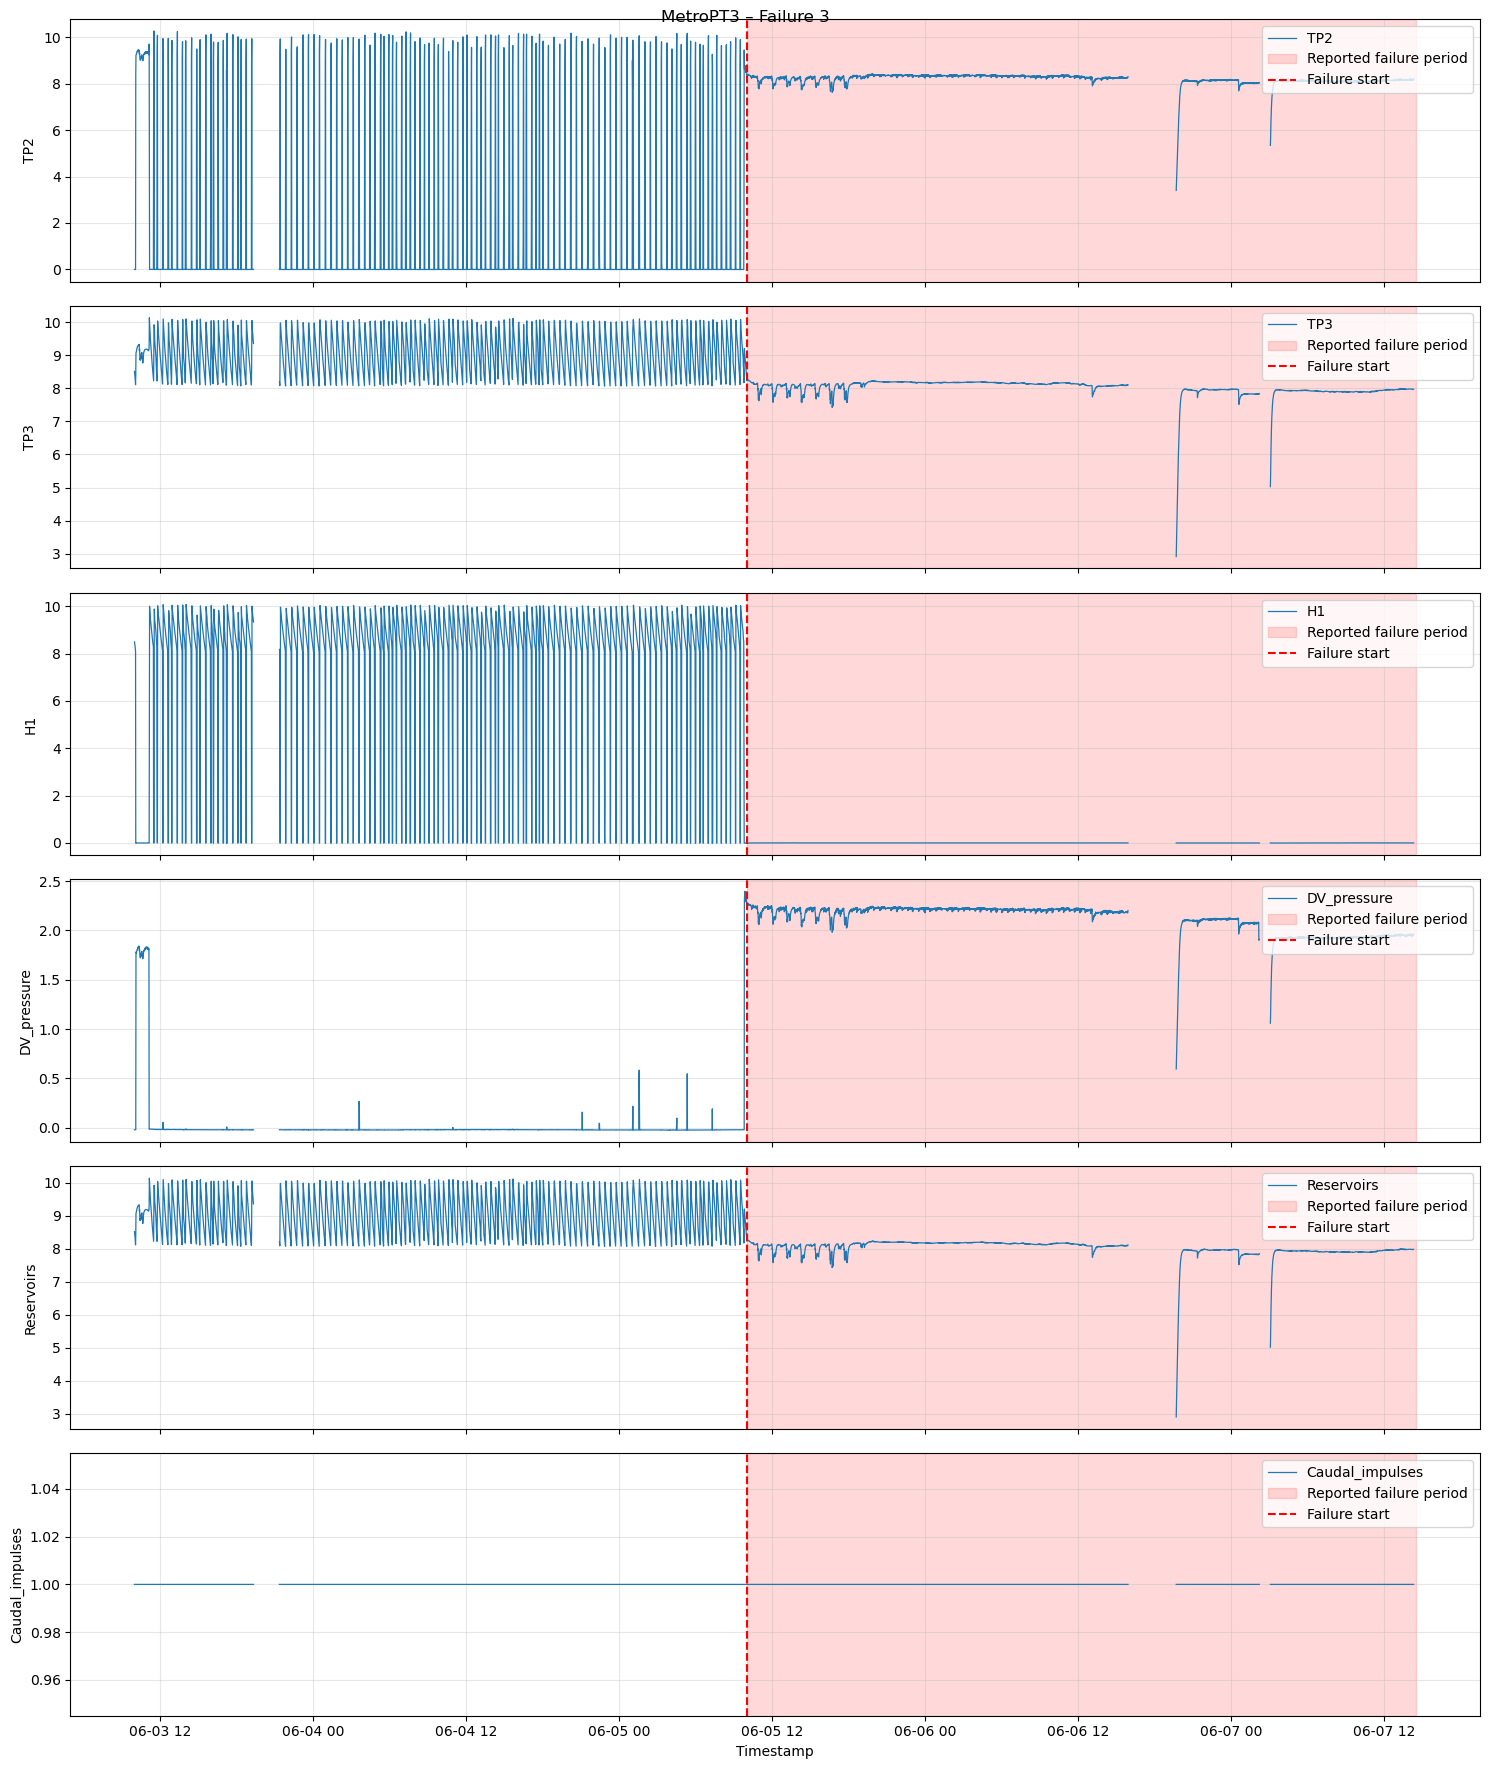

In [42]:
plot_failure_window(
    ts_df,
    failure_events,
    failure_id=3,
    hours_before=48,
    hours_after=6
)

##### Sensor analysis group 2: Compressor Operation

In [43]:
def plot_failure_window(
    ts_df,
    failure_events,
    failure_id,
    hours_before=48,
    hours_after=6,
    sensors=None
):
    if sensors is None:
        sensors = sensor_groups['Compressor Operation']

    event = failure_events.loc[
        failure_events['failure_id'] == failure_id
    ].iloc[0]

    failure_start = event['start_time']
    failure_end = event['end_time']

    window_start = failure_start - pd.Timedelta(hours=hours_before)
    window_end = failure_end + pd.Timedelta(hours=hours_after)

    subset = ts_df.loc[window_start:window_end, sensors]

    # 1-minute medians for a readable overview
    subset_plot = subset.resample('1min').median()

    fig, axes = plt.subplots(
        len(sensors), 1,
        figsize=(15, 3 * len(sensors)),
        sharex=True,
        squeeze=False
    )

    for ax, sensor in zip(axes.flat, sensors):
        ax.plot(
            subset_plot.index,
            subset_plot[sensor],
            linewidth=0.9,
            label=sensor
        )

        ax.axvspan(
            failure_start,
            failure_end,
            color='red',
            alpha=0.15,
            label='Reported failure period'
        )

        ax.axvline(
            failure_start,
            color='red',
            linestyle='--',
            label='Failure start'
        )

        ax.set_ylabel(sensor)
        ax.legend(loc='upper right')
        ax.grid(alpha=0.3)

    axes[-1, 0].set_xlabel('Timestamp')
    fig.suptitle(f'MetroPT3 – Failure {failure_id}')
    plt.tight_layout()
    plt.show()

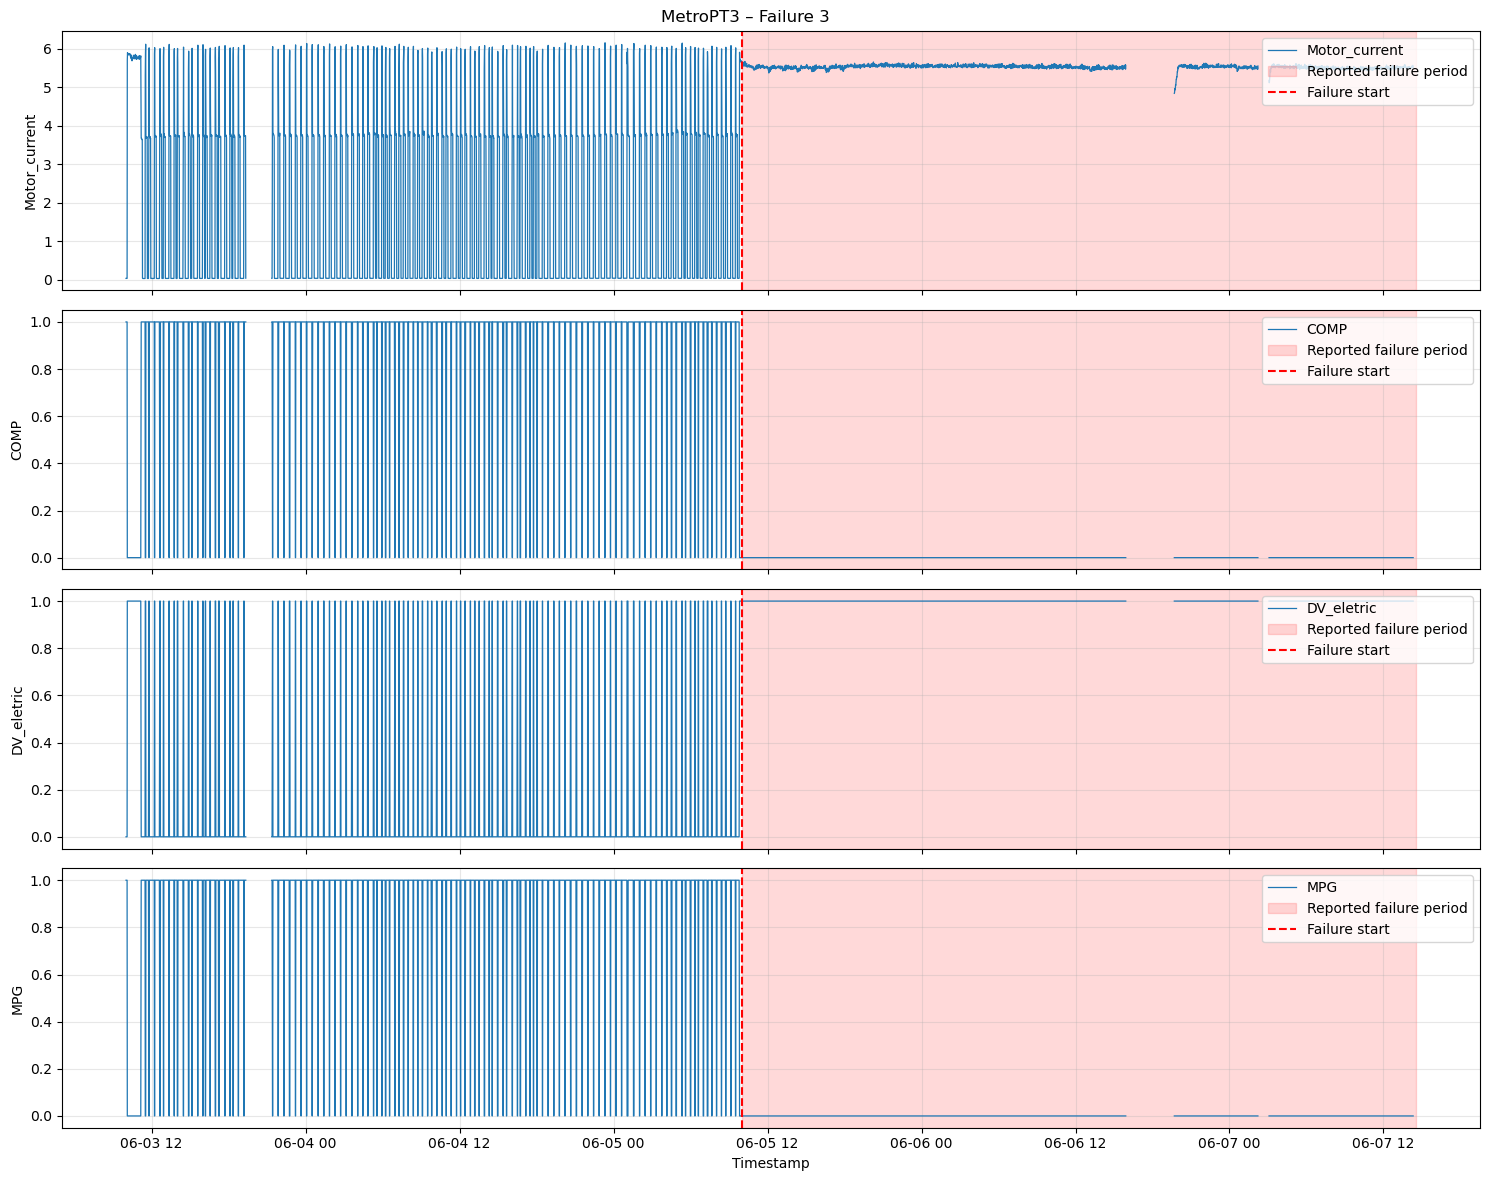

In [44]:
plot_failure_window(
    ts_df,
    failure_events,
    failure_id=3,
    hours_before=48,
    hours_after=6
)

##### Sensor analysis group 3: Temperature, Dryers and Safety

In [45]:
def plot_failure_window(
    ts_df,
    failure_events,
    failure_id,
    hours_before=48,
    hours_after=6,
    sensors=None
):
    if sensors is None:
        sensors = sensor_groups['Temperature, Dryers and Safety']

    event = failure_events.loc[
        failure_events['failure_id'] == failure_id
    ].iloc[0]

    failure_start = event['start_time']
    failure_end = event['end_time']

    window_start = failure_start - pd.Timedelta(hours=hours_before)
    window_end = failure_end + pd.Timedelta(hours=hours_after)

    subset = ts_df.loc[window_start:window_end, sensors]

    # 1-minute medians for a readable overview
    subset_plot = subset.resample('1min').median()

    fig, axes = plt.subplots(
        len(sensors), 1,
        figsize=(15, 3 * len(sensors)),
        sharex=True,
        squeeze=False
    )

    for ax, sensor in zip(axes.flat, sensors):
        ax.plot(
            subset_plot.index,
            subset_plot[sensor],
            linewidth=0.9,
            label=sensor
        )

        ax.axvspan(
            failure_start,
            failure_end,
            color='red',
            alpha=0.15,
            label='Reported failure period'
        )

        ax.axvline(
            failure_start,
            color='red',
            linestyle='--',
            label='Failure start'
        )

        ax.set_ylabel(sensor)
        ax.legend(loc='upper right')
        ax.grid(alpha=0.3)

    axes[-1, 0].set_xlabel('Timestamp')
    fig.suptitle(f'MetroPT3 – Failure {failure_id}')
    plt.tight_layout()
    plt.show()

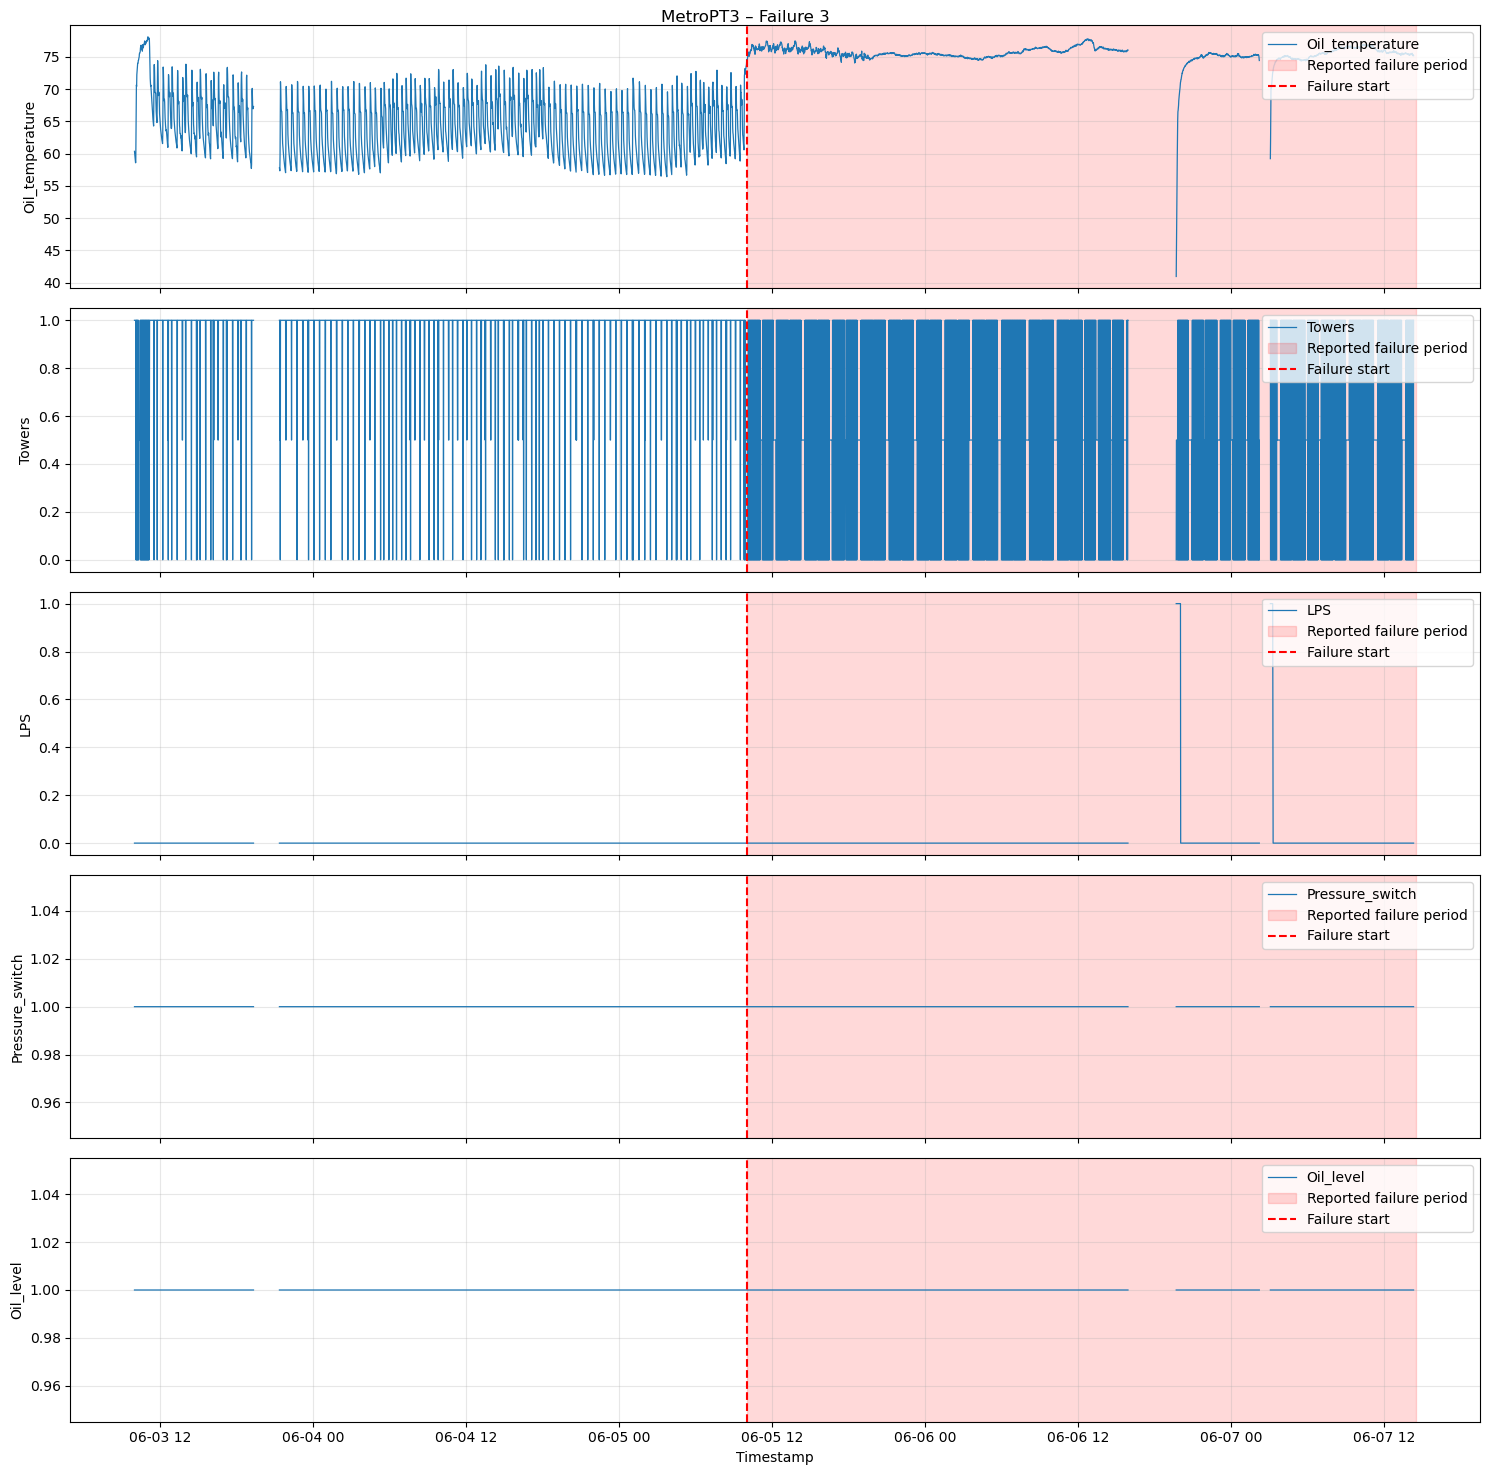

In [46]:
plot_failure_window(
    ts_df,
    failure_events,
    failure_id=3,
    hours_before=48,
    hours_after=6
)

#### Examining sensor behavior across three periods

In [47]:
event = failure_events.loc[
    failure_events['failure_id'] == 3
].iloc[0]

t = event['start_time']

# Define periods without overlapping timestamps
periods = {
    '48–24h before': ts_df.loc[
        (ts_df.index >= t - pd.Timedelta(hours=48)) &
        (ts_df.index < t - pd.Timedelta(hours=24))
    ],
    '24–0h before': ts_df.loc[
        (ts_df.index >= t - pd.Timedelta(hours=24)) &
        (ts_df.index < t)
    ],
    'During failure': ts_df.loc[
        (ts_df.index >= t) &
        (ts_df.index <= event['end_time'])
    ]
}

# Get all sensors from the existing sensor_groups dictionary
all_sensors = [
    sensor
    for sensors in sensor_groups.values()
    for sensor in sensors
]

# Calculate mean for each sensor in each period
results = []

for name, data in periods.items():
    row = {'Period': name}

    for sensor in all_sensors:
        row[sensor] = data[sensor].mean()

    results.append(row)

comparison = pd.DataFrame(results).set_index('Period')

display(comparison.round(2))

,TP2,TP3,H1,DV_pressure,Reservoirs,Caudal_impulses,Motor_current,COMP,DV_eletric,MPG,Oil_temperature,Towers,LPS,Pressure_switch,Oil_level
Period,,,,,,,,,,,,,,,
48–24h before,1.33,9.01,7.64,0.07,9.01,1.0,1.97,0.85,0.15,0.85,64.71,0.93,0.00,1.0,1.0
24–0h before,0.99,9.02,7.97,0.00,9.02,1.0,1.78,0.89,0.11,0.89,63.83,0.94,0.00,1.0,1.0
During failure,7.89,8.02,-0.01,2.02,8.02,1.0,5.49,0.00,1.00,0.00,75.52,0.50,0.01,1.0,1.0


#### Conclusion Failure 3

- **During the failure** the compressor again runs continuously under load, this time for the longest window (52.5 h): Motor_current about 5.5 A, COMP/MPG = 0, DV_eletric = 1, TP2 about 7.9 bar, H1 about 0, Oil_temperature about 75.5 °C. TP3 and Reservoirs show the largest average drop of Failures 1–3 (about 9.0 → 8.0 bar).
- **Before the failure** the compressor cycles normally until about 10:00 on 5 June. The differences between the two pre-failure periods are small (Motor_current 1.97 vs 1.78 A, Oil_temperature 64.7 vs 63.8 °C).
- There is a data gap inside the failure window, on the afternoon and evening of 6 June.
- **Early-warning potential:** low at this resolution. The onset is abrupt.

#### Identifying pattern Failure 4

##### Sensor analysis group 1: Pressure and Airflow

In [48]:
def plot_failure_window(
    ts_df,
    failure_events,
    failure_id,
    hours_before=48,
    hours_after=6,
    sensors=None
):
    if sensors is None:
        sensors = sensor_groups['Pressure and Airflow']

    event = failure_events.loc[
        failure_events['failure_id'] == failure_id
    ].iloc[0]

    failure_start = event['start_time']
    failure_end = event['end_time']

    window_start = failure_start - pd.Timedelta(hours=hours_before)
    window_end = failure_end + pd.Timedelta(hours=hours_after)

    subset = ts_df.loc[window_start:window_end, sensors]

    # 1-minute medians for a readable overview
    subset_plot = subset.resample('1min').median()

    fig, axes = plt.subplots(
        len(sensors), 1,
        figsize=(15, 3 * len(sensors)),
        sharex=True,
        squeeze=False
    )

    for ax, sensor in zip(axes.flat, sensors):
        ax.plot(
            subset_plot.index,
            subset_plot[sensor],
            linewidth=0.9,
            label=sensor
        )

        ax.axvspan(
            failure_start,
            failure_end,
            color='red',
            alpha=0.15,
            label='Reported failure period'
        )

        ax.axvline(
            failure_start,
            color='red',
            linestyle='--',
            label='Failure start'
        )

        ax.set_ylabel(sensor)
        ax.legend(loc='upper right')
        ax.grid(alpha=0.3)

    axes[-1, 0].set_xlabel('Timestamp')
    fig.suptitle(f'MetroPT3 – Failure {failure_id}')
    plt.tight_layout()
    plt.show()

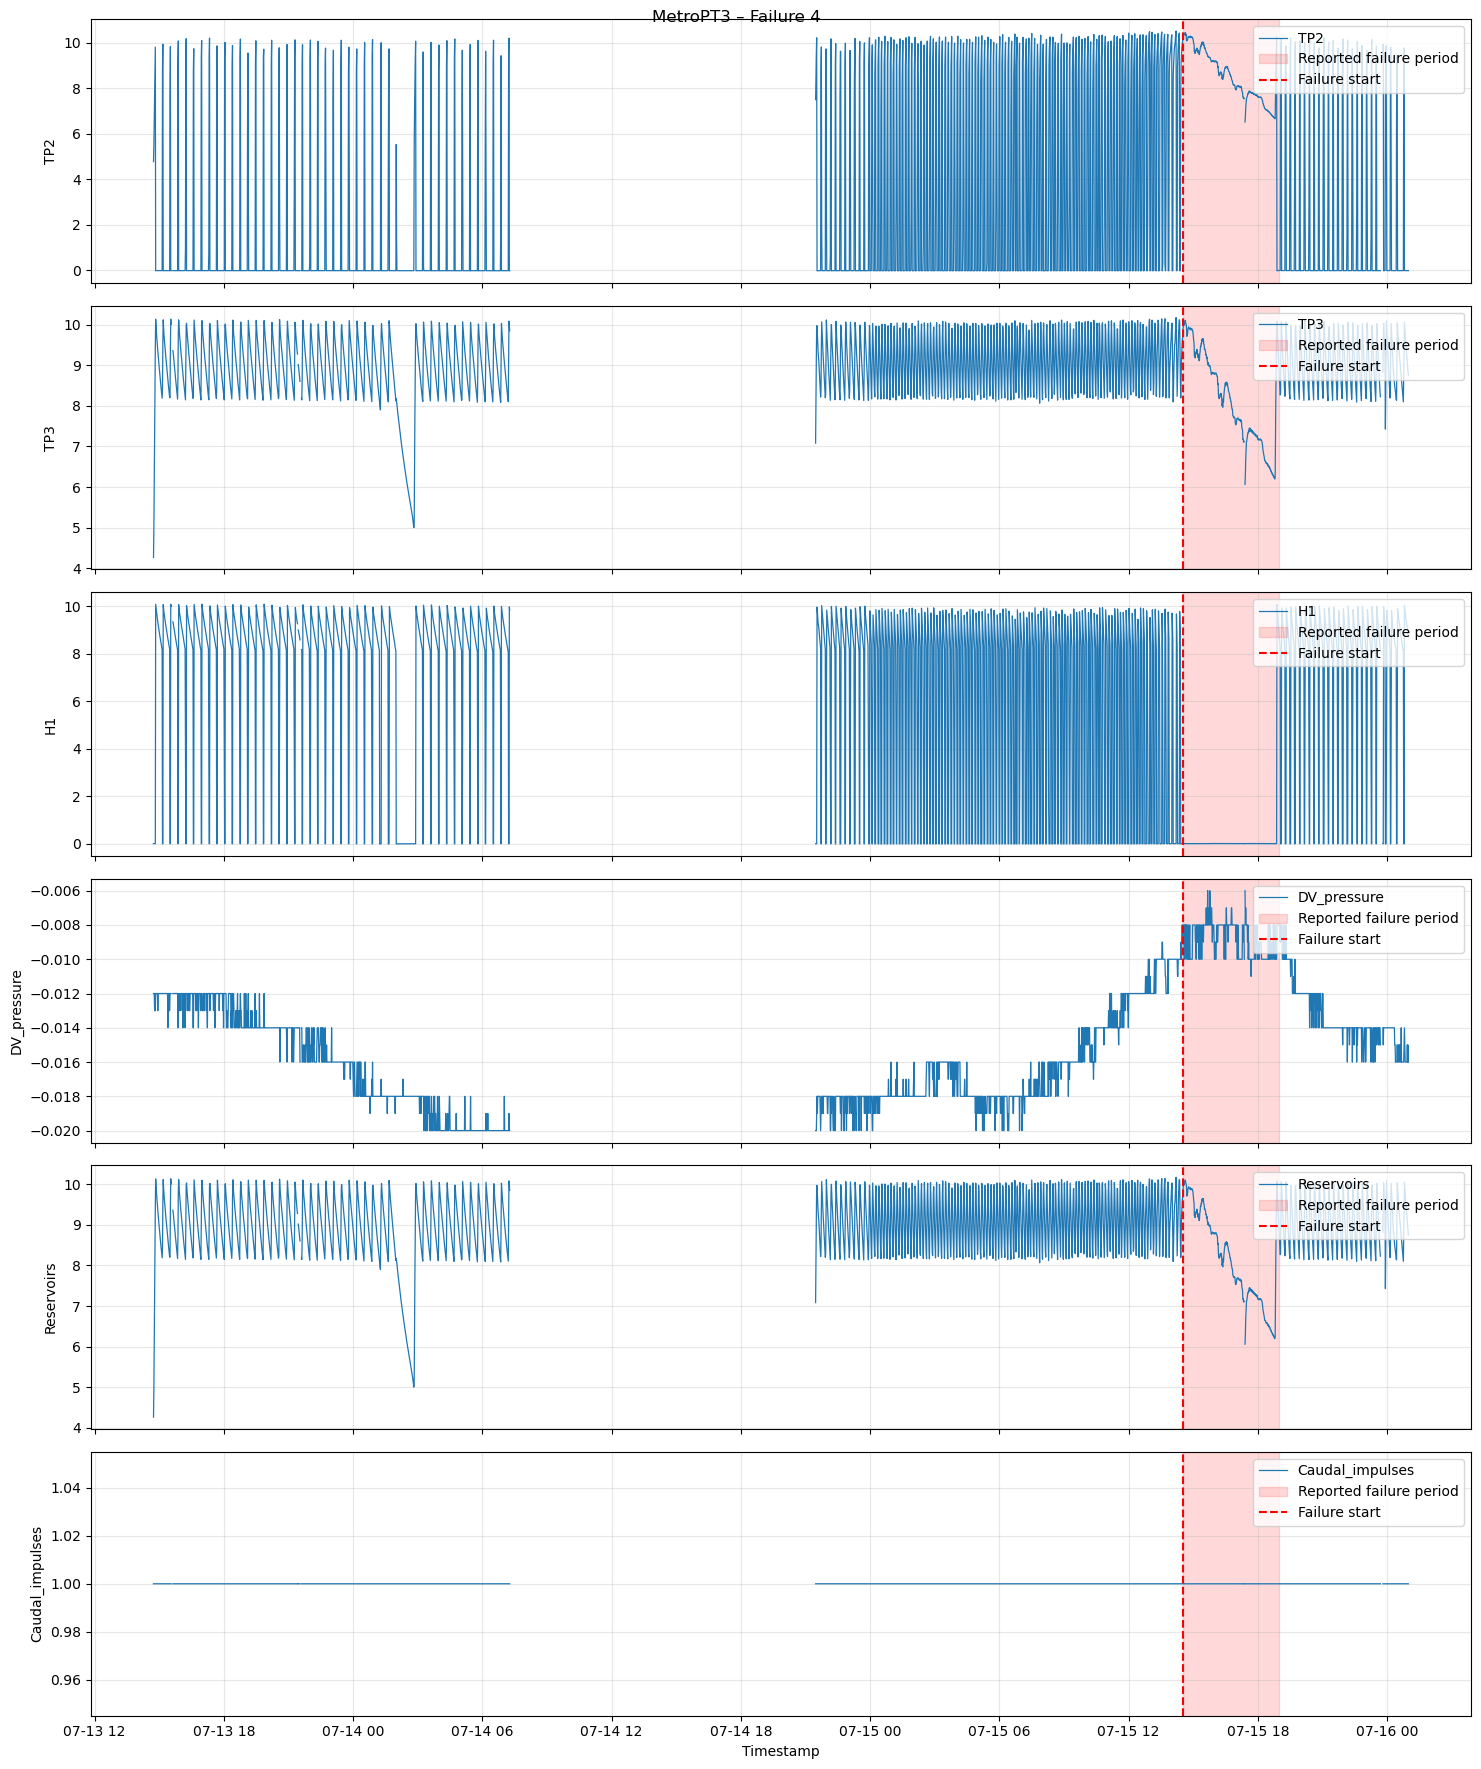

In [49]:
plot_failure_window(
    ts_df,
    failure_events,
    failure_id=4,
    hours_before=48,
    hours_after=6
)

##### Sensor analysis group 2: Compressor Operation

In [50]:
def plot_failure_window(
    ts_df,
    failure_events,
    failure_id,
    hours_before=48,
    hours_after=6,
    sensors=None
):
    if sensors is None:
        sensors = sensor_groups['Compressor Operation']

    event = failure_events.loc[
        failure_events['failure_id'] == failure_id
    ].iloc[0]

    failure_start = event['start_time']
    failure_end = event['end_time']

    window_start = failure_start - pd.Timedelta(hours=hours_before)
    window_end = failure_end + pd.Timedelta(hours=hours_after)

    subset = ts_df.loc[window_start:window_end, sensors]

    # 1-minute medians for a readable overview
    subset_plot = subset.resample('1min').median()

    fig, axes = plt.subplots(
        len(sensors), 1,
        figsize=(15, 3 * len(sensors)),
        sharex=True,
        squeeze=False
    )

    for ax, sensor in zip(axes.flat, sensors):
        ax.plot(
            subset_plot.index,
            subset_plot[sensor],
            linewidth=0.9,
            label=sensor
        )

        ax.axvspan(
            failure_start,
            failure_end,
            color='red',
            alpha=0.15,
            label='Reported failure period'
        )

        ax.axvline(
            failure_start,
            color='red',
            linestyle='--',
            label='Failure start'
        )

        ax.set_ylabel(sensor)
        ax.legend(loc='upper right')
        ax.grid(alpha=0.3)

    axes[-1, 0].set_xlabel('Timestamp')
    fig.suptitle(f'MetroPT3 – Failure {failure_id}')
    plt.tight_layout()
    plt.show()

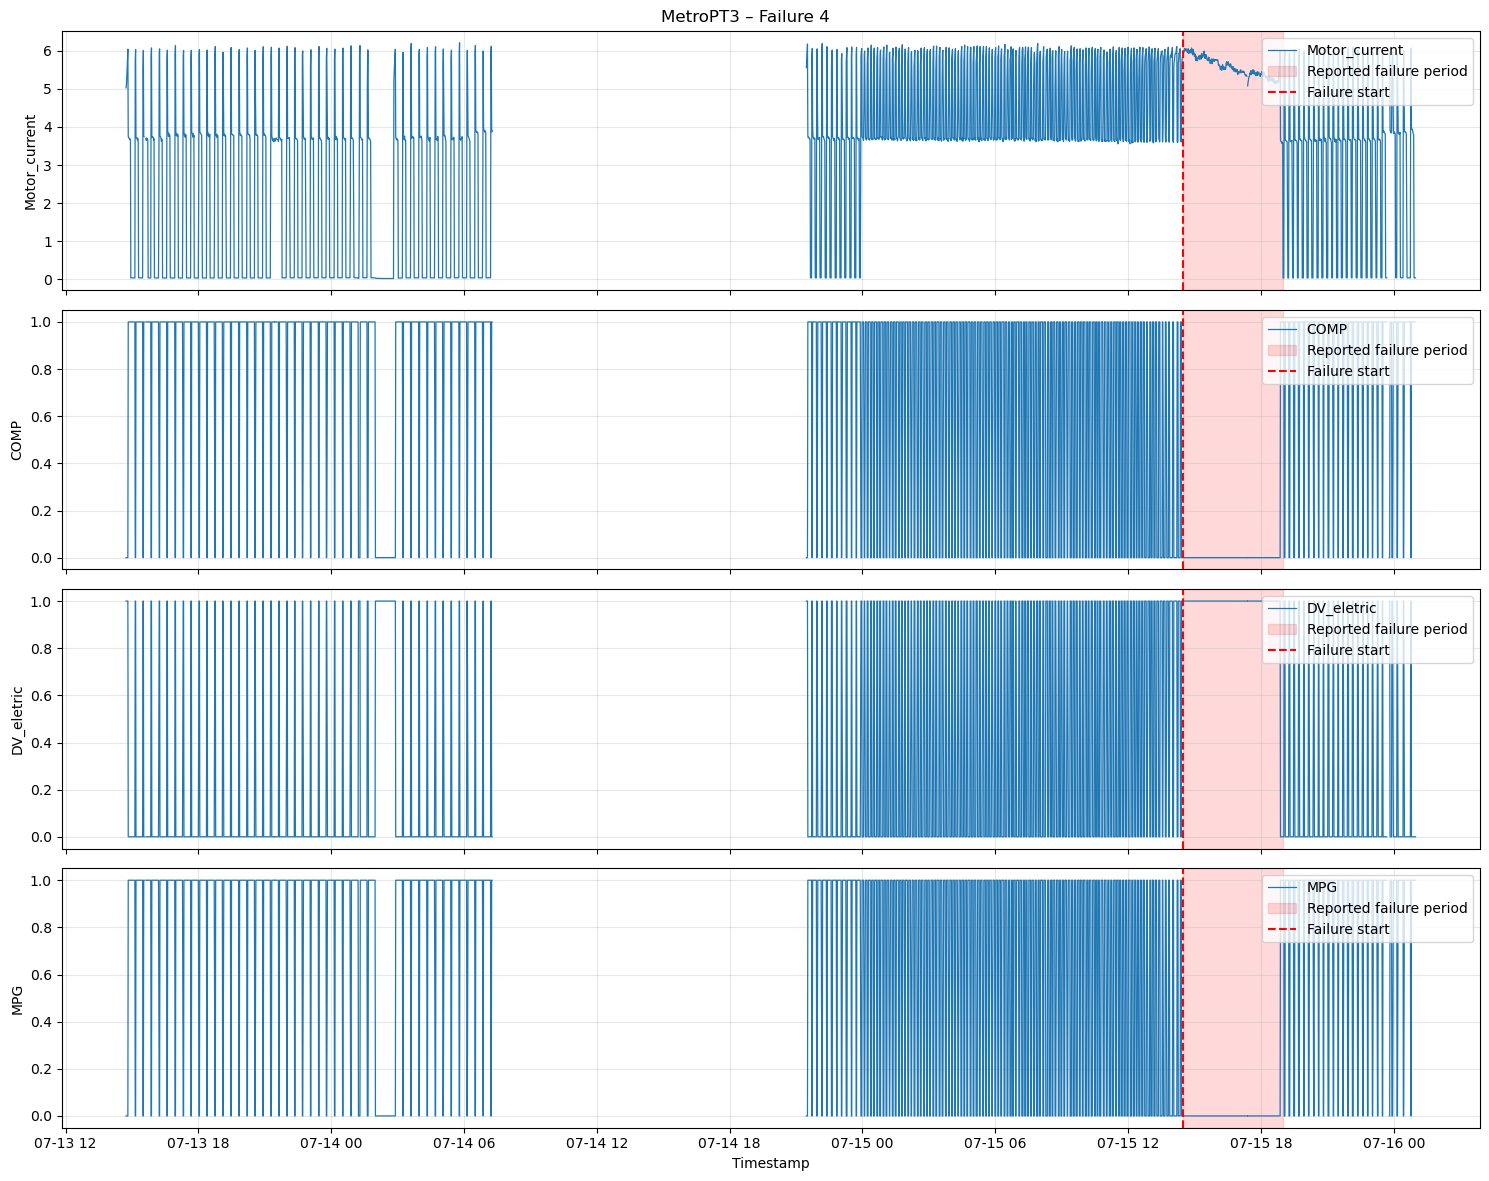

In [51]:
plot_failure_window(
    ts_df,
    failure_events,
    failure_id=4,
    hours_before=48,
    hours_after=6
)

##### Sensor analysis group 3: Temperature, Dryers and Safety

In [52]:
def plot_failure_window(
    ts_df,
    failure_events,
    failure_id,
    hours_before=48,
    hours_after=6,
    sensors=None
):
    if sensors is None:
        sensors = sensor_groups['Temperature, Dryers and Safety']

    event = failure_events.loc[
        failure_events['failure_id'] == failure_id
    ].iloc[0]

    failure_start = event['start_time']
    failure_end = event['end_time']

    window_start = failure_start - pd.Timedelta(hours=hours_before)
    window_end = failure_end + pd.Timedelta(hours=hours_after)

    subset = ts_df.loc[window_start:window_end, sensors]

    # 1-minute medians for a readable overview
    subset_plot = subset.resample('1min').median()

    fig, axes = plt.subplots(
        len(sensors), 1,
        figsize=(15, 3 * len(sensors)),
        sharex=True,
        squeeze=False
    )

    for ax, sensor in zip(axes.flat, sensors):
        ax.plot(
            subset_plot.index,
            subset_plot[sensor],
            linewidth=0.9,
            label=sensor
        )

        ax.axvspan(
            failure_start,
            failure_end,
            color='red',
            alpha=0.15,
            label='Reported failure period'
        )

        ax.axvline(
            failure_start,
            color='red',
            linestyle='--',
            label='Failure start'
        )

        ax.set_ylabel(sensor)
        ax.legend(loc='upper right')
        ax.grid(alpha=0.3)

    axes[-1, 0].set_xlabel('Timestamp')
    fig.suptitle(f'MetroPT3 – Failure {failure_id}')
    plt.tight_layout()
    plt.show()

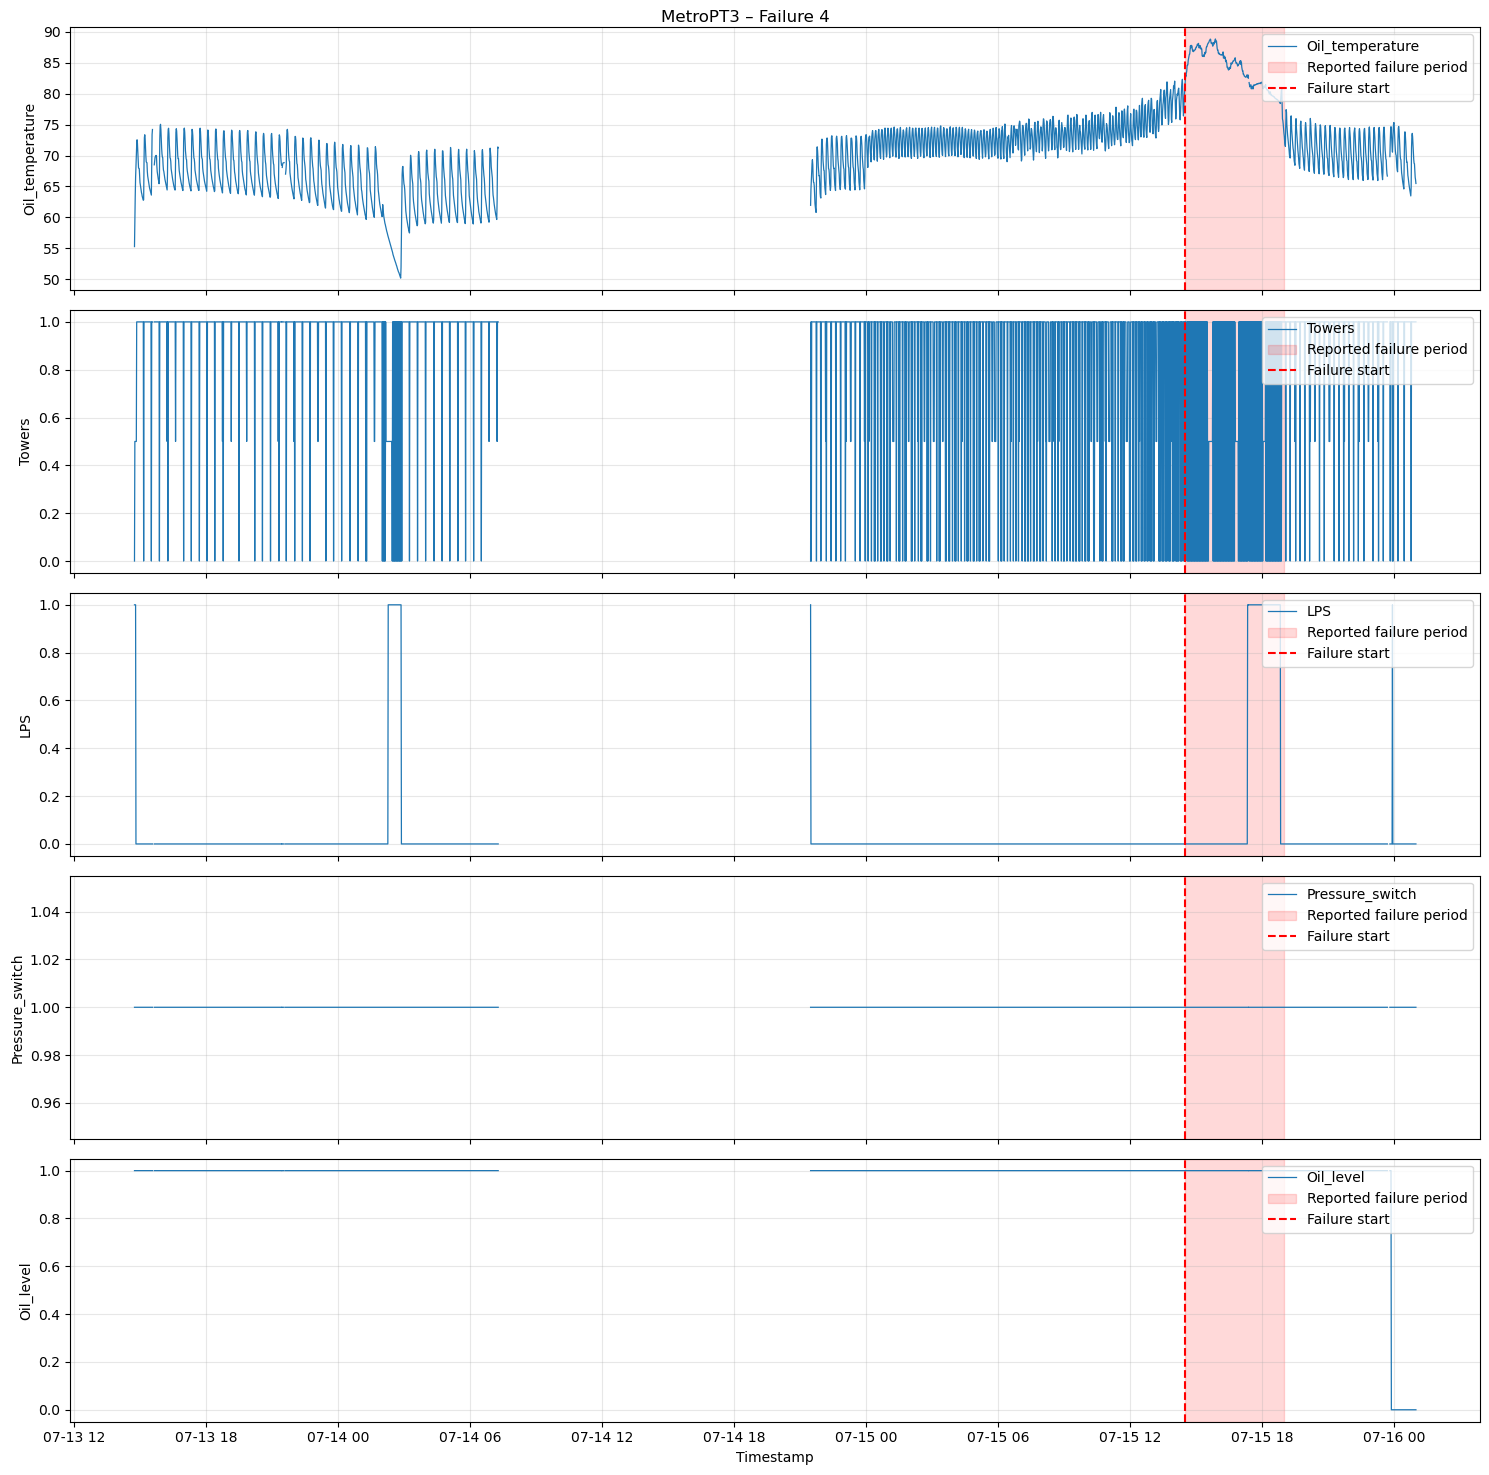

In [53]:
plot_failure_window(
    ts_df,
    failure_events,
    failure_id=4,
    hours_before=48,
    hours_after=6
)

#### Examining sensor behavior across three periods

In [54]:
event = failure_events.loc[
    failure_events['failure_id'] == 4
].iloc[0]

t = event['start_time']

# Define periods without overlapping timestamps
periods = {
    '48–24h before': ts_df.loc[
        (ts_df.index >= t - pd.Timedelta(hours=48)) &
        (ts_df.index < t - pd.Timedelta(hours=24))
    ],
    '24–0h before': ts_df.loc[
        (ts_df.index >= t - pd.Timedelta(hours=24)) &
        (ts_df.index < t)
    ],
    'During failure': ts_df.loc[
        (ts_df.index >= t) &
        (ts_df.index <= event['end_time'])
    ]
}

# Get all sensors from the existing sensor_groups dictionary
all_sensors = [
    sensor
    for sensors in sensor_groups.values()
    for sensor in sensors
]

# Calculate mean for each sensor in each period
results = []

for name, data in periods.items():
    row = {'Period': name}

    for sensor in all_sensors:
        row[sensor] = data[sensor].mean()

    results.append(row)

comparison = pd.DataFrame(results).set_index('Period')

display(comparison.round(2))

,TP2,TP3,H1,DV_pressure,Reservoirs,Caudal_impulses,Motor_current,COMP,DV_eletric,MPG,Oil_temperature,Towers,LPS,Pressure_switch,Oil_level
Period,,,,,,,,,,,,,,,
48–24h before,0.95,8.88,7.57,-0.01,8.88,1.0,1.80,0.84,0.16,0.84,65.59,0.92,0.04,1.0,1.0
24–0h before,3.62,9.11,5.49,-0.00,9.11,1.0,4.37,0.61,0.39,0.61,72.79,0.80,0.00,1.0,1.0
During failure,8.27,8.21,0.25,-0.01,8.21,1.0,5.51,0.03,0.97,0.03,83.91,0.51,0.33,1.0,1.0


#### Conclusion Failure 4

- **During the failure** the compressor runs continuously under load (Motor_current about 5.5 A, COMP/MPG close to 0, DV_eletric close to 1), and the pressure cannot be maintained: TP3 and Reservoirs fall steadily from about 10 to about 6.2 bar, and LPS (pressure < 7 bar) is active 33 % of the time. Oil_temperature reaches about 84 °C, the highest of all four failures. Failure 4 is therefore the most severe event.
- **Before the failure**, unlike Failures 1–3, there is a clear precursor. In the 24 h before the failure the compressor switches on much more often than in the 48–24h period: Motor_current 1.80 → 4.37 A, DV_eletric 0.16 → 0.39, TP2 0.95 → 3.62 bar, Oil_temperature 65.6 → 72.8 °C. This fits an air leak: the pressure drops faster, so the compressor has to reload more frequently. The plots show that from about 00:00 on 15 July (around 14 h before the failure) the motor no longer switches off between load cycles (it stays offloaded at about 3.7 A), and Oil_temperature rises steadily from about 72 to about 80 °C.
- There is a long data gap on 14 July (about 07:00 to 22:00) and a sharp pressure drop in the early hours of 14 July.
- **Early-warning potential:** high. The rising load-cycle frequency is visible many hours before the reported failure start.

### Overall conclusion: sensor behavior around the failures

- **Common failure signature:** in all four failures the compressor leaves its normal on/off cycling and stays in continuous loaded operation (Motor_current about 5.5 A, COMP = MPG = 0, DV_eletric = 1, H1 about 0, TP2 about 8 bar, Oil_temperature 74–84 °C), while TP3/Reservoirs pressure drops. This fits an air leak: the compressor runs constantly but cannot hold the pressure.
- **Precursors:** only Failure 4 shows a clear change before the failure window (more frequent load cycles, higher mean Motor_current and Oil_temperature in the 24 h before). Failures 1–3 start abruptly when viewed with 24-hour means and 1-minute plots.
- **Implication for early warning:** detecting the failure window itself is easy, but this is detection, not early warning. For early warning, the next step is to derive features that describe the duty cycle, such as load cycles per hour, share of time under load, and pressure-decay rate during off phases. These may reveal slower degradation that 24-hour means average out.
- **Data gaps** occur shortly before several failures and must be handled when lead times are evaluated.